# 03 — Experimentos: C4.5 y Random Forest

Este notebook concentra los ejemplos y las pruebas de ambos clasificadores: comprueba cálculos conocidos, prepara datos discretos, continuos y mixtos, compara los modelos sobre los mismos casos y explora distintas configuraciones. Reúne tablas de métricas, tiempos, matrices de confusión y gráficos. Las implementaciones de los algoritmos se cargan como definiciones, sin copiarlas ni exigir la ejecución previa de otro kernel.

Un **experimento de clasificación** entrena un modelo con atributos y respuestas conocidas y luego compara sus predicciones con las respuestas de otros casos. La comparación solo es justa si ambos modelos reciben los mismos casos, etiquetas y particiones. Las transformaciones particulares de cada modelo se aprenden exclusivamente en entrenamiento. Los identificadores se conservan como índices y nunca se usan como atributos.

### Qué se compara en cada modelo

**C4.5:** aprende un árbol que pregunta por atributos hasta llegar a una hoja. En cada nodo, la proporción de una clase es $p_c=W_c/W$, donde $W_c$ suma sus pesos y $W$ suma los de todas las clases. La entropía $H=-\sum_c p_c\log_2p_c$ mide su mezcla. Una división con ramas de masas $W_j$ reduce esa mezcla en $G=H-\sum_j(W_j/W)H_j$. Se selecciona la mayor razón $R=G/I$, con $I=-\sum_j(W_j/W)\log_2(W_j/W)$, para moderar la preferencia por atributos con muchas categorías. Las categorías crean una rama por valor y los números crean dos ramas, $A\leq t$ y $A>t$, eligiendo un corte observado en entrenamiento. Una hoja responde con su clase más probable. Se usa la convención $0\log_2 0=0$ y se descartan divisiones sin dos ramas conocidas.

Los faltantes de C4.5 conservan la información del caso sin inventar el atributo: la ganancia se calcula sobre los conocidos y se multiplica por su proporción $W_K/W$. La información de partición incluye además la masa desconocida como un grupo de cálculo. Cada caso ausente se reparte con peso $w_iW_j/W_K$ entre las ramas y, al consultar un atributo ausente, se mezclan sus probabilidades con esas mismas proporciones. Una categoría nueva usa las frecuencias del nodo alcanzado. Se aplican límites de profundidad, masa mínima y ganancia para detener el crecimiento; son controles de prepoda.

**Random Forest:** combina árboles de divisiones binarias construidos con aleatoriedad. El bootstrap obtiene muestras con reemplazo y la selección aleatoria de atributos por nodo busca diversificar los árboles. Cada árbol reduce Gini $1-\sum_c p_c^2$ o entropía, según su configuración. El bosque promedia las probabilidades de sus $B$ árboles, $\overline P(c\mid x)=B^{-1}\sum_b P_b(c\mid x)$, y elige la clase de mayor valor. Sus categorías se codifican como columnas indicadoras, una por categoría aprendida (**one-hot**); una categoría nueva produce ceros en ese grupo. En la comparación con faltantes, los números ausentes se reemplazan por la mediana de entrenamiento y las categorías ausentes por la categoría más frecuente de entrenamiento. La mediana es el valor central de los números ordenados. Ninguna transformación aprende de validación o prueba.

**Diferencias de diseño:** el árbol propio selecciona mediante razón de ganancia y conserva categorías como ramas; el bosque utiliza impureza, codificación y promedio de árboles. Por lo tanto, se comparan los procedimientos completos con sus preparaciones correspondientes. Los nombres de clase se conservan como texto y ambos predictores entregan una columna `prediccion` con los mismos índices de entrada.

### Protocolo y decisiones de diseño

1. **Referencia inicial:** se reserva un 20 % de cada dataset para prueba, con estratificación por clase y semilla 42. La estratificación conserva aproximadamente las proporciones de clases, sujeta al redondeo de filas. Se entrenan configuraciones iniciales fijas sin elegir parámetros mirando sus resultados de prueba.
2. **Exploración:** el 80 % restante se divide nuevamente, reservando un 25 % de ese bloque para validación. Quedan aproximadamente 60 % para aprender, 20 % para validar y 20 % para prueba. Cada combinación de parámetros entrena un modelo nuevo y se evalúa en entrenamiento y validación.
3. **Selección:** por modelo y dataset se elige el mayor F1 macro de validación. Un empate conserva la primera configuración del orden generado por la grilla. Luego se reentrena con todo el 80 % original y se evalúa una vez en prueba. La exploración no usa prueba para decidir. La referencia inicial es descriptiva; tampoco se usa para cambiar las grillas.
4. **Faltantes:** se comparan 0 %, 5 %, 15 % y 30 % nominales de ausencias aleatorias en las características de entrenamiento y prueba, con tres semillas de máscara (42, 43 y 44). Ambos algoritmos reciben la misma máscara en cada condición. C4.5 distribuye pesos y Random Forest imputa dentro de su pipeline. Se mantienen fijas las particiones, la semilla del bosque y una configuración por algoritmo; no se seleccionan parámetros por los resultados de esta batería. Las mismas semillas generan máscaras anidadas al aumentar el porcentaje, para comparar cada condición con su referencia sin nulos adicionales adicionales.

Un resultado alto en entrenamiento y menor en validación o prueba puede indicar **sobreajuste**: el modelo se adapta demasiado a detalles de los casos que ya vio. La brecha $F1_{entrenamiento}-F1_{prueba}$ ayuda a describirlo, pero una sola partición no permite establecer una conclusión general.

### Métricas de clasificación

Para cada clase $c$, se la considera positiva frente a todas las demás. $TP_c$ cuenta aciertos de esa clase; $FP_c$, casos de otras clases predichos como $c$; $FN_c$, casos de $c$ predichos como otra clase. Con $N$ casos, $K$ clases y soporte $n_c$:

$$Accuracy=\frac{\text{cantidad de aciertos}}N,\qquad
Precision_c=\frac{TP_c}{TP_c+FP_c},\qquad Recall_c=\frac{TP_c}{TP_c+FN_c},$$
$$F1_c=\frac{2TP_c}{2TP_c+FP_c+FN_c},\qquad
M_{macro}=\frac1K\sum_c M_c,\qquad
M_{weighted}=\sum_c\frac{n_c}N M_c.$$

Se calculan Precision, Recall y F1 con ambos promedios. **Macro** da igual importancia a cada clase; **weighted** pondera por su frecuencia. F1 macro es el promedio de los F1 individuales, no el F1 calculado a partir de Precision macro y Recall macro. Una división sin denominador se informa como cero para ambos modelos (`zero_division=0`). Todas las métricas se expresan entre 0 y 1.

La **matriz de confusión** contiene $C_{ij}$, cantidad de casos cuya clase real es $i$ y cuya predicción es $j$. Sus filas son respuestas reales y sus columnas son predicciones. Se registra el orden explícito de las clases de entrenamiento para interpretar tanto la matriz como las métricas.

### Medición de tiempos y reproducibilidad

$$t_{entrenamiento}=1000(t_{fin}-t_{inicio}),\qquad
t_{inferencia,S}=1000(t_{fin,S}-t_{inicio,S})\quad\text{en milisegundos}.$$

El entrenamiento incluye construir el modelo, validar la entrada y aprender su preparación y sus decisiones. La inferencia incluye validar y transformar los casos y devolver sus predicciones como DataFrame. Se excluyen carga de archivos, particionado, inyección de faltantes, métricas y gráficos. El tiempo de entrenamiento se repite en las filas de los conjuntos evaluados de una misma ejecución: no debe sumarse como si fueran entrenamientos diferentes.

Se registran parámetros efectivos, semillas, versiones, índices y predicciones. Repetir datos, configuraciones y entorno debe reproducir las predicciones y métricas; los tiempos pueden variar. Las comparaciones iniciales y la exploración tienen una corrida por configuración. La batería de faltantes repite tres máscaras por porcentaje y resume media y desvío; esas repeticiones no varían la partición ni constituyen una medición estable del costo de cómputo. No se interpreta una diferencia pequeña de tiempos como una ventaja concluyente.



In [1]:
# Herramientas para cargar definiciones en espacios separados y localizar archivos.
from pathlib import Path
from hashlib import sha256
from io import BytesIO
from itertools import product
from math import isclose
from time import perf_counter
import json
import platform
import sys
import types

# Tablas, números, gráficos y métricas compartidas por los dos clasificadores.
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# Encontrar los archivos tanto desde la raíz del proyecto como desde notebooks/.
for carpeta in (Path.cwd(), *Path.cwd().parents):
    if (carpeta / "notebooks/01_decision_tree_c45.ipynb").is_file():
        RAIZ = carpeta
        break
else:
    raise FileNotFoundError("Ejecutá desde la carpeta del proyecto o desde notebooks/.")


if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))


def cargar_definiciones(nombre_archivo, etiqueta):
    """Carga solo celdas etiquetadas como definiciones, sin ejecutar experimentos."""
    # Un módulo separado evita mezclar nombres internos de los algoritmos.
    ruta = RAIZ / "notebooks" / nombre_archivo
    contenido = json.loads(ruta.read_text(encoding="utf-8"))
    nombre_modulo = "implementacion_" + ruta.stem
    modulo = types.ModuleType(nombre_modulo)
    sys.modules[nombre_modulo] = modulo
    celdas = [celda for celda in contenido["cells"]
              if celda["cell_type"] == "code"
              and etiqueta in celda.get("metadata", {}).get("tags", [])]
    if not celdas:
        raise ValueError(f"No se encontraron definiciones para {nombre_archivo}.")
    for celda in celdas:
        exec(compile("".join(celda["source"]), str(ruta), "exec"), modulo.__dict__)
    return modulo


# Reutilizar el código real de los algoritmos, conservando sus módulos independientes.
modulo_arbol = cargar_definiciones("01_decision_tree_c45.ipynb", "c45-definiciones")
modulo_bosque = cargar_definiciones("02_random_forest.ipynb", "rf-definiciones")
SEMILLA_PARTICION = 42
SEMILLA_MODELOS = 42
VERSIONES = dict(python=platform.python_version(), numpy=np.__version__,
                 pandas=pd.__version__, sklearn=sklearn.__version__)


## 1. Ejemplos de cálculo y verificaciones pequeñas

Antes de medir rendimiento se comprueba que los cálculos básicos tengan sentido. En un conjunto de 15 casos con 6 respuestas `no` y 9 `si`, una división con una rama de 6 `si` y otra de 6 `no` más 3 `si` produce:

$$H=0{,}970951,\quad H_A=0{,}550978,\quad G=0{,}419973,\quad I=0{,}970951,\quad R=0{,}432538.$$

La tabla artificial representa decisiones de préstamo. Sus categorías son texto y el identificador es solo el índice. Se conserva el ejemplo completo para observar qué atributo se elige y verificarlo con valores independientes del programa.

También se comprueban un corte numérico perfecto, un atributo que se reutiliza para reconocer un intervalo, una relación XOR y una ausencia. **XOR** asigna una clase cuando las dos categorías coinciden y otra cuando difieren: la primera división no reduce la impureza, pero la siguiente sí. Para `medida=[1,2,None]` y clases `[A,B,A]`, la probabilidad esperada ante una consulta ausente es $P(A)=2/3$ y $P(B)=1/3$.


In [2]:
# Tabla artificial de 15 casos: el identificador queda fuera de los atributos.
from io import StringIO
prestamos = pd.read_csv(StringIO("""identificador edad trabajo vivienda credito objetivo
1 joven no no regular no
2 joven no no bueno no
3 joven si no bueno si
4 joven si si regular si
5 joven no no regular no
6 media no no regular no
7 media no no bueno no
8 media si si bueno si
9 media no si excelente si
10 media no si excelente si
11 mayor no si excelente si
12 mayor no si bueno si
13 mayor si no bueno si
14 mayor si no excelente si
15 mayor no no regular no
"""), sep=r"\s+", dtype=str).set_index("identificador")
caracteristicas_prestamos = prestamos.drop(columns="objetivo")
objetivos_prestamos = prestamos[["objetivo"]]

# Calcular y mostrar las medidas de cada atributo sin copiar el algoritmo.
medidas_atributos = []
for atributo in caracteristicas_prestamos:
    evaluacion = modulo_arbol.particion_categorica(
        caracteristicas_prestamos[atributo], objetivos_prestamos["objetivo"])
    medidas_atributos.append({"atributo": atributo, **{
        medida: evaluacion[medida] for medida in
        ("entropia_ponderada", "ganancia", "split_info", "gain_ratio")}})
tabla_medidas = pd.DataFrame(medidas_atributos).set_index("atributo")
assert isclose(modulo_arbol.entropia(objetivos_prestamos["objetivo"]), 0.9709505944546686)
for medida, esperado in dict(entropia_ponderada=0.5509775004326937,
                             ganancia=0.4199730940219749, split_info=0.9709505944546686,
                             gain_ratio=0.4325380677663126).items():
    assert isclose(tabla_medidas.loc["vivienda", medida], esperado, abs_tol=1e-12)
arbol_prestamos = modulo_arbol.ArbolC45().entrenar(
    caracteristicas_prestamos, objetivos_prestamos)
assert arbol_prestamos.raiz_.atributo == "vivienda"
assert arbol_prestamos.predecir(caracteristicas_prestamos)["prediccion"].tolist() == prestamos["objetivo"].tolist()
display(tabla_medidas)

# Verificar un límite numérico y la reutilización de una medida en varios niveles.
corte = modulo_arbol.buscar_mejor_umbral([1, 2, 3, 4], ["A", "A", "B", "B"])
assert corte["umbral"] == 2 and corte["gain_ratio"] == 1
caracteristicas_intervalo = pd.DataFrame({"medida": [1, 2, 3, 4, 5, 6]})
objetivos_intervalo = pd.DataFrame({"objetivo": ["A", "A", "B", "B", "A", "A"]})
arbol_intervalo = modulo_arbol.ArbolC45().entrenar(caracteristicas_intervalo, objetivos_intervalo)
assert arbol_intervalo.predecir(caracteristicas_intervalo)["prediccion"].tolist() == objetivos_intervalo["objetivo"].tolist()
assert any(hijo.atributo == "medida" for hijo in arbol_intervalo.raiz_.hijos.values())

# Verificar que la prepoda pueda impedir una separación que comienza con ganancia cero.
caracteristicas_xor = pd.DataFrame({"primera": ["0", "0", "1", "1"],
                                    "segunda": ["0", "1", "0", "1"]})
objetivos_xor = pd.DataFrame({"objetivo": ["A", "B", "B", "A"]})
arbol_xor = modulo_arbol.ArbolC45().entrenar(caracteristicas_xor, objetivos_xor)
assert arbol_xor.raiz_.ganancia == 0
assert arbol_xor.predecir(caracteristicas_xor)["prediccion"].tolist() == objetivos_xor["objetivo"].tolist()
assert modulo_arbol.ArbolC45(umbral_ganancia=0.01).entrenar(caracteristicas_xor, objetivos_xor).raiz_.es_hoja

# Contrastar el reparto probabilístico de un faltante con el resultado manual.
arbol_manual = modulo_arbol.ArbolC45().entrenar(
    pd.DataFrame({"medida": [1, 2, None]}), pd.DataFrame({"objetivo": ["A", "B", "A"]}))
probabilidades_manuales = arbol_manual.predecir_probabilidades(pd.DataFrame({"medida": [None]}))
assert isclose(probabilidades_manuales.iloc[0]["A"], 2 / 3)
assert isclose(probabilidades_manuales.iloc[0]["B"], 1 / 3)
display(probabilidades_manuales)
print("Cálculos manuales, cortes, reutilización, prepoda y probabilidades: correctos.")


,entropia_ponderada,ganancia,split_info,gain_ratio
atributo,,,,
edad,0.887943,0.083007,1.584963,0.052372
trabajo,0.647300,0.323650,0.918296,0.352447
vivienda,0.550978,0.419973,0.970951,0.432538
credito,0.607961,0.362990,1.565596,0.231854


,A,B
0,0.666667,0.333333


Cálculos manuales, cortes, reutilización, prepoda y probabilidades: correctos.


## 2. Datos y preparación reproducible

Los tres problemas son de clasificación: discreto, continuo y mixto describen los **atributos**, no la salida. Se conservan las copias locales de los datos y se verifica su huella SHA-256, un resumen de sus bytes que permite detectar cambios accidentales. Iris está incluido en scikit-learn. No se requiere conexión a Internet para cargarlos.

| Dataset | Tipo de atributos | Casos × atributos | Clases y cantidades | Entrenamiento / prueba |
|---|---|---|---|---|
| Contact Lenses (`lenses`) | Discreto | 24 × 4 | `rigidos`: 4; `blandos`: 5; `sin_lentes`: 15 | 19 / 5 |
| Iris (`iris`) | Continuo | 150 × 4 | `setosa`, `versicolor`, `virginica`: 50 cada una | 120 / 30 |
| Heart Disease Cleveland (`heart`) | Mixto | 303 × 13 | `ausencia`: 164; `presencia`: 139 | 242 / 61 |

**Contact Lenses:** combina grupos de edad (`joven`, `prepresbicia`, `presbicia`), prescripción (`miopia`, `hipermetropia`), astigmatismo (`no`, `si`) y producción de lágrimas (`reducida`, `normal`). Los códigos de salida 1, 2 y 3 se transforman en `rigidos`, `blandos` y `sin_lentes`. El identificador de cada fila se usa como índice.

**Iris:** contiene largo y ancho de sépalo y pétalo, en centímetros. Las cuatro medidas son numéricas. Se conservan las etiquetas de sus tres especies y los nombres originales de las columnas de entrada.

**Heart:** se consideran numéricos `edad`, `presion_reposo`, `colesterol`, `frecuencia_maxima`, `depresion_st` y `vasos` (cantidad de vasos observados). Se consideran categóricos `sexo`, `dolor_pecho`, `glucemia_alta`, `ecg`, `angina_ejercicio`, `pendiente_st` y `thal`; sus códigos pasan a texto. `pendiente_st` se trata como categoría sin imponer un orden. La salida original 0 significa `ausencia` y los valores de 1 a 4 se agrupan como `presencia`. Estas etiquetas describen el problema del dataset y las métricas no incorporan costos clínicos diferenciados.

Lenses e Iris están completos. Cleveland contiene seis celdas ausentes, en seis casos: cuatro en `vasos` y dos en `thal`. Se leen los signos `?` como ausencia; sus 303 filas se conservan. Las copias anteriores de Statlog se retiran de la versión actual y permanecen en el historial Git; esta comparación utiliza Cleveland. No se eliminan filas, equilibran clases ni imputan datos al cargarlas. C4.5 recibe categorías y números originales; Random Forest aprende su codificación interna con entrenamiento. En Lenses, un acierto en prueba cambia Accuracy en 20 puntos porcentuales, por lo que sus resultados tienen una resolución muy limitada.


In [3]:
# La preparación común conserva tipos, índices y las seis ausencias naturales de Cleveland.
from datos_tp import cargar_datasets, TAMANOS, CLASES
TAMANOS_ESPERADOS = TAMANOS
CLASES_ESPERADAS = CLASES


def cargar_datos_experimentales():
    """Devuelve atributos, objetivos y tipo con la preparación compartida por la interfaz."""
    return {nombre: dict(caracteristicas=datos["X"], objetivos=datos["y"], tipo=datos["tipo"])
            for nombre, datos in cargar_datasets().items()}


def preparar_particiones(caracteristicas, objetivos, semilla=42):
    """Devuelve referencia 80/20 y selección interna, con índices originales."""
    # Reservar prueba antes de cualquier búsqueda de configuraciones.
    (caracteristicas_entrenamiento, caracteristicas_prueba,
     objetivos_entrenamiento, objetivos_prueba) = train_test_split(
        caracteristicas, objetivos, test_size=0.20, random_state=semilla,
        shuffle=True, stratify=objetivos["objetivo"])

    # Separar validación exclusivamente dentro del bloque de entrenamiento.
    (caracteristicas_ajuste, caracteristicas_validacion,
     objetivos_ajuste, objetivos_validacion) = train_test_split(
        caracteristicas_entrenamiento, objetivos_entrenamiento,
        test_size=0.25, random_state=semilla, shuffle=True,
        stratify=objetivos_entrenamiento["objetivo"])
    return {
        "referencia": {
            "entrenamiento": (caracteristicas_entrenamiento, objetivos_entrenamiento),
            "prueba": (caracteristicas_prueba, objetivos_prueba)},
        "seleccion": {
            "entrenamiento": (caracteristicas_ajuste, objetivos_ajuste),
            "validacion": (caracteristicas_validacion, objetivos_validacion)},
    }


In [4]:
# Cargar las tablas y revisar dimensiones, clases, ausencia de nulos y tipos numéricos.
datasets = cargar_datos_experimentales()
particiones = {}
resumen_datos = []
for nombre, datos in datasets.items():
    caracteristicas, objetivos = datos["caracteristicas"], datos["objetivos"]
    assert caracteristicas.shape == TAMANOS_ESPERADOS[nombre]
    assert objetivos.shape == (len(caracteristicas), 1)
    assert caracteristicas.index.is_unique and caracteristicas.index.equals(objetivos.index)
    assert not objetivos.isna().any().any()
    assert int(caracteristicas.isna().to_numpy().sum()) == (6 if nombre == "heart" else 0)
    numericas = caracteristicas.select_dtypes(include="number")
    valores_numericos = numericas.to_numpy(dtype=float)
    assert np.isfinite(valores_numericos[~np.isnan(valores_numericos)]).all()
    assert objetivos["objetivo"].value_counts().to_dict() == CLASES_ESPERADAS[nombre]
    particiones[nombre] = preparar_particiones(caracteristicas, objetivos, SEMILLA_PARTICION)
    resumen_datos.append({
        "dataset": nombre, "tipo": datos["tipo"], "casos": len(caracteristicas),
        "atributos": caracteristicas.shape[1],
        "entrenamiento_exploracion": len(particiones[nombre]["seleccion"]["entrenamiento"][0]),
        "validacion": len(particiones[nombre]["seleccion"]["validacion"][0]),
        "entrenamiento_final": len(particiones[nombre]["referencia"]["entrenamiento"][0]),
        "prueba": len(particiones[nombre]["referencia"]["prueba"][0]),
    })

# Mostrar las versiones y las cantidades realmente utilizadas, incluido el redondeo.
display(pd.Series(VERSIONES, name="version"))
display(pd.DataFrame(resumen_datos).set_index("dataset"))


python     3.14.7
numpy       2.5.4
pandas      3.0.6
sklearn     1.9.1
Name: version, dtype: str

,tipo,casos,atributos,entrenamiento_exploracion,validacion,entrenamiento_final,prueba
dataset,,,,,,,
lenses,discreto,24,4,14,5,19,5
iris,continuo,150,4,90,30,120,30
heart,mixto,303,13,181,61,242,61


## 3. Motor común de comparación

El motor recibe el nombre y tipo de dataset, sus conjuntos ya separados y una grilla independiente por modelo. Una **grilla** asigna a cada parámetro una lista de valores: se recorren todas las combinaciones del producto cartesiano. Una grilla vacía representa una configuración con todos los valores iniciales. Los nombres se recorren ordenados y los valores mantienen el orden indicado. Cada configuración construye un modelo nuevo.

Un error identifica modelo, parámetros y causa y detiene la ejecución; no se descartan combinaciones silenciosamente. Antes de entrenar se verifican alineación y separación de conjuntos. Los índices deben ser únicos en el protocolo experimental para poder comprobar que no se comparte un caso entre conjuntos, aunque los predictores también admitan consultas con índices duplicados.

| Campo de resultado | Contenido |
|---|---|
| `id_ejecucion`, `dataset`, `tipo_datos`, `modelo` | Identificación del entrenamiento y del problema. |
| `fase`, `escenario`, `conjunto` | Referencia, exploración o final; datos completos o con nulos; entrenamiento, validación o prueba. |
| `configuracion`, `parametros` | Número de combinación y valores efectivos, incluidos los valores iniciales. |
| `semilla_particion`, `semilla_modelo`, `semilla_nulos`, `versiones` | Información necesaria para repetir la corrida. C4.5 no usa aleatoriedad propia. |
| `cantidad_casos`, `orden_clases` | Tamaño evaluado y orden explícito de clases. |
| `accuracy`, `precision_macro`, `recall_macro`, `f1_macro` | Exactitud y métricas con igual peso por clase. |
| `precision_weighted`, `recall_weighted`, `f1_weighted` | Métricas ponderadas por cantidad de casos reales de cada clase. |
| `matriz_confusion`, `indices`, `predicciones` | Resultados completos para comprobar correspondencia y reproducibilidad. |
| `tiempo_entrenamiento_ms`, `tiempo_inferencia_ms` | Costos medidos por separado, en milisegundos. |
| `fraccion_nulos_observada` | Proporción real de celdas ausentes del conjunto evaluado. |

La semilla del modelo se recibe por separado de las grillas para que quede una sola fuente de configuración. La política de división por cero y el orden de clases son comunes a ambos algoritmos.


In [5]:
# Nombres comunes de las métricas y orden estable para mostrar los resultados.
METRICAS = ["accuracy", "precision_macro", "recall_macro", "f1_macro",
            "precision_weighted", "recall_weighted", "f1_weighted"]


def expandir_grilla(grilla):
    """Devuelve todas las combinaciones en orden estable; una grilla vacía da una."""
    # Una lista vacía suele ser un error de configuración, no una corrida omitida.
    if not isinstance(grilla, dict):
        raise TypeError("Cada grilla debe ser un diccionario de listas de valores.")
    nombres = sorted(grilla)
    for nombre in nombres:
        if not isinstance(grilla[nombre], (list, tuple)) or len(grilla[nombre]) == 0:
            raise ValueError(f"La grilla de {nombre} debe tener una lista no vacía.")
    return [dict(zip(nombres, valores)) for valores in product(*(grilla[nombre] for nombre in nombres))]


def validar_conjuntos(conjuntos):
    """Comprueba alineación, columnas y ausencia de casos compartidos entre bloques."""
    # Entrenamiento es obligatorio; el resto solo puede ser validación o prueba.
    if not isinstance(conjuntos, dict) or "entrenamiento" not in conjuntos:
        raise ValueError("Se requiere un conjunto de entrenamiento.")
    if set(conjuntos) - {"entrenamiento", "validacion", "prueba"}:
        raise ValueError("Los conjuntos admitidos son entrenamiento, validacion y prueba.")
    columnas = None
    indices_usados = set()
    for nombre, (caracteristicas, objetivos) in conjuntos.items():
        if not isinstance(caracteristicas, pd.DataFrame) or not isinstance(objetivos, pd.DataFrame):
            raise TypeError(f"{nombre}: características y objetivos deben ser DataFrames.")
        if caracteristicas.empty or list(objetivos.columns) != ["objetivo"]:
            raise ValueError(f"{nombre}: se necesitan casos, atributos y una columna objetivo.")
        if not caracteristicas.index.equals(objetivos.index) or not caracteristicas.index.is_unique:
            raise ValueError(f"{nombre}: índices desalineados o duplicados.")
        if objetivos.isna().any().any():
            raise ValueError(f"{nombre}: las respuestas no pueden tener faltantes.")
        if columnas is None:
            columnas = caracteristicas.columns
        if not caracteristicas.columns.equals(columnas):
            raise ValueError(f"{nombre}: las columnas deben coincidir en nombre y orden.")
        indices = set(caracteristicas.index)
        if indices_usados.intersection(indices):
            raise ValueError(f"{nombre}: hay casos compartidos entre conjuntos.")
        indices_usados.update(indices)


def calcular_metricas(objetivos, predicciones, clases):
    """Calcula métricas y matriz con orden de clases y política de ceros comunes."""
    # Comprobar correspondencia antes de transformar las columnas en vectores.
    if list(predicciones.columns) != ["prediccion"] or not objetivos.index.equals(predicciones.index):
        raise ValueError("Las predicciones deben conservar índice, orden y columna prediccion.")
    reales = objetivos["objetivo"].tolist()
    estimadas = predicciones["prediccion"].tolist()
    if not set(reales).union(estimadas).issubset(set(clases)):
        raise ValueError("Aparecieron clases que no estaban en entrenamiento.")

    # Calcular ambos promedios sobre el mismo orden completo de clases.
    medidas = {"accuracy": accuracy_score(reales, estimadas)}
    for promedio in ("macro", "weighted"):
        precision, sensibilidad, f1, _ = precision_recall_fscore_support(
            reales, estimadas, labels=clases, average=promedio, zero_division=0)
        medidas.update({f"precision_{promedio}": precision,
                        f"recall_{promedio}": sensibilidad, f"f1_{promedio}": f1})
    medidas["matriz_confusion"] = confusion_matrix(reales, estimadas, labels=clases).tolist()
    return medidas


def ejecutar_grillas(nombre_dataset, tipo_datos, conjuntos, grillas, fase="referencia",
                      escenario="completo", semilla_particion=42, semilla_modelo=42,
                      semilla_nulos=None):
    """Entrena un modelo por combinación y devuelve una fila por conjunto evaluado.

    Los conjuntos llegan ya separados. Las métricas y la presentación quedan
    fuera de los cronómetros. Una configuración inválida detiene la corrida.
    """
    # Verificar que ambos algoritmos reciban las mismas tablas y un protocolo válido.
    validar_conjuntos(conjuntos)
    caracteristicas_entrenamiento, objetivos_entrenamiento = conjuntos["entrenamiento"]
    clases = list(dict.fromkeys(objetivos_entrenamiento["objetivo"]))
    registros = []
    if not isinstance(grillas, dict) or not grillas:
        raise ValueError("Se requiere al menos una grilla de modelo.")
    for nombre_modelo, grilla in grillas.items():
        try:
            combinaciones = expandir_grilla(grilla)
        except (TypeError, ValueError) as error:
            raise ValueError(f"Modelo {nombre_modelo}; grilla {grilla!r}: {error}") from error
        for numero_configuracion, parametros in enumerate(combinaciones, start=1):
            try:
                # Cronometrar creación, preparación y aprendizaje del modelo nuevo.
                inicio = perf_counter()
                if nombre_modelo == "C4.5":
                    modelo = modulo_arbol.ArbolC45(**parametros).entrenar(
                        caracteristicas_entrenamiento, objetivos_entrenamiento)
                    predecir = modelo.predecir
                    parametros_efectivos = modelo.obtener_parametros()
                elif nombre_modelo == "Random Forest":
                    modelo = modulo_bosque.entrenar_bosque(
                        caracteristicas_entrenamiento, objetivos_entrenamiento,
                        semilla=semilla_modelo, **parametros)
                    predecir = modulo_bosque.crear_predictor(modelo)
                    parametros_efectivos = modelo.configuracion_.copy()
                else:
                    raise ValueError("Modelo desconocido; usar C4.5 o Random Forest.")
                tiempo_entrenamiento = 1000 * (perf_counter() - inicio)

                # Cronometrar cada consulta y calcular sus métricas después.
                for nombre_conjunto, (caracteristicas, objetivos) in conjuntos.items():
                    inicio = perf_counter()
                    predicciones = predecir(caracteristicas)
                    tiempo_inferencia = 1000 * (perf_counter() - inicio)
                    medidas = calcular_metricas(objetivos, predicciones, clases)
                    registros.append(dict(
                        id_ejecucion=f"{nombre_dataset}-{escenario}-{fase}-{nombre_modelo}-{numero_configuracion}",
                        dataset=nombre_dataset, tipo_datos=tipo_datos, modelo=nombre_modelo,
                        fase=fase, escenario=escenario, conjunto=nombre_conjunto,
                        configuracion=numero_configuracion, parametros=parametros_efectivos.copy(),
                        semilla_particion=semilla_particion,
                        semilla_modelo=semilla_modelo if nombre_modelo == "Random Forest" else None,
                        semilla_nulos=semilla_nulos, versiones=VERSIONES.copy(),
                        cantidad_casos=len(caracteristicas), orden_clases=clases.copy(),
                        indices=caracteristicas.index.tolist(),
                        predicciones=predicciones["prediccion"].tolist(),
                        fraccion_nulos_observada=float(caracteristicas.isna().to_numpy().mean()),
                        tiempo_entrenamiento_ms=tiempo_entrenamiento,
                        tiempo_inferencia_ms=tiempo_inferencia, **medidas))
            except (TypeError, ValueError, RuntimeError) as error:
                raise ValueError(f"Modelo {nombre_modelo}; configuración {parametros!r}; causa: {error}") from error
    return pd.DataFrame(registros)


def seleccionar_por_validacion(resultados):
    """Construye una grilla de un valor por parámetro con el mejor F1 de validación."""
    # Impedir que una tabla con resultados de prueba intervenga en esta selección.
    if "prueba" in set(resultados["conjunto"]):
        raise ValueError("La selección no acepta resultados de prueba.")
    validacion = resultados[resultados["conjunto"].eq("validacion")]
    if validacion.empty or validacion["dataset"].nunique() != 1:
        raise ValueError("Se necesita validación de exactamente un dataset.")
    grillas_elegidas = {}
    for modelo, candidatos in validacion.groupby("modelo", sort=False):
        elegido = candidatos.sort_values(["f1_macro", "configuracion"], ascending=[False, True]).iloc[0]
        parametros = elegido["parametros"].copy()
        if modelo == "Random Forest":
            # Quitar valores fijos o registrados por separado de la configuración editable.
            for nombre in ("semilla", "procesos", "minimo_muestras_division", "minimo_muestras_hoja"):
                parametros.pop(nombre)
        grillas_elegidas[modelo] = {nombre: [valor] for nombre, valor in parametros.items()}
    return grillas_elegidas


def inyectar_faltantes(conjuntos, fraccion, semilla):
    """Copia los conjuntos y oculta atributos al azar, sin modificar las etiquetas."""
    # La misma semilla genera la misma máscara; no se consultan respuestas correctas.
    if not isinstance(fraccion, (int, float)) or not 0 <= fraccion <= 1:
        raise ValueError("La fracción de faltantes debe estar entre 0 y 1.")
    generador = np.random.default_rng(semilla)
    copias = {}
    for nombre, (caracteristicas, objetivos) in conjuntos.items():
        mascara = generador.random(caracteristicas.shape) < fraccion
        copias[nombre] = (caracteristicas.mask(mascara), objetivos.copy(deep=True))
    return copias


def ejecutar_bateria_faltantes(datasets, particiones, grillas,
                               fracciones=(0.0, 0.05, 0.15, 0.30),
                               semillas_nulos=(42, 43, 44)):
    """Compara los modelos con máscaras compartidas y devuelve todas las corridas.

    Las particiones y los parámetros permanecen fijos. Solo cambia la máscara
    de valores ausentes, con una semilla identificable por repetición.
    """
    # Evitar escenarios duplicados o una batería sin referencia completa.
    fracciones, semillas_nulos = tuple(fracciones), tuple(semillas_nulos)
    if (not fracciones or 0.0 not in fracciones or len(set(fracciones)) != len(fracciones)
            or any(isinstance(valor, bool) or not isinstance(valor, (int, float))
                   or not 0 <= valor <= 1 for valor in fracciones)):
        raise ValueError("Las fracciones deben ser distintas, estar entre 0 y 1 e incluir 0.")
    if (not semillas_nulos or len(set(semillas_nulos)) != len(semillas_nulos)
            or any(isinstance(semilla, bool) or not isinstance(semilla, int)
                   or semilla < 0 for semilla in semillas_nulos)):
        raise ValueError("Se necesitan semillas enteras no negativas y distintas.")
    if set(grillas) != {"C4.5", "Random Forest"}:
        raise ValueError("La batería debe comparar C4.5 y Random Forest.")
    if any(len(expandir_grilla(grilla)) != 1 for grilla in grillas.values()):
        raise ValueError("Usá una configuración fija por modelo para aislar el efecto de los nulos.")

    # Una máscara se construye una sola vez y se entrega a ambos algoritmos.
    tablas = []
    for nombre, datos in datasets.items():
        referencia = particiones[nombre]["referencia"]
        for repeticion, semilla_nulos in enumerate(semillas_nulos, start=1):
            for fraccion in fracciones:
                conjuntos = inyectar_faltantes(referencia, fraccion, semilla_nulos)
                resultados = ejecutar_grillas(
                    nombre, datos["tipo"], conjuntos, grillas, fase="robustez",
                    escenario=f"nulos_{fraccion:g}", semilla_nulos=semilla_nulos,
                    semilla_particion=SEMILLA_PARTICION, semilla_modelo=SEMILLA_MODELOS)
                resultados["fraccion_nulos_objetivo"] = float(fraccion)
                resultados["repeticion"] = repeticion
                resultados["id_ejecucion"] += f"-repeticion_{repeticion}"
                tablas.append(resultados)
    return pd.concat(tablas, ignore_index=True)


def resumir_bateria_faltantes(resultados):
    """Devuelve promedios, dispersión y caídas emparejadas frente al 0 % de nulos."""
    # Asociar cada corrida a su referencia de igual dataset, modelo y semilla.
    claves_pareja = ["dataset", "modelo", "conjunto", "configuracion",
                    "repeticion", "semilla_nulos"]
    referencia = resultados.loc[resultados["fraccion_nulos_objetivo"].eq(0),
                                 claves_pareja + ["accuracy", "f1_macro"]].rename(
                                     columns={"accuracy": "accuracy_sin_nulos",
                                              "f1_macro": "f1_macro_sin_nulos"})
    diferencias = resultados.merge(referencia, on=claves_pareja, how="left", validate="many_to_one")
    if diferencias[["accuracy_sin_nulos", "f1_macro_sin_nulos"]].isna().any().any():
        raise ValueError("Cada corrida necesita una referencia sin nulos de la misma repetición.")

    # Caída positiva indica deterioro; negativa indica una mejora en esa corrida.
    diferencias["caida_accuracy_pp"] = 100 * (diferencias["accuracy_sin_nulos"] - diferencias["accuracy"])
    diferencias["caida_f1_macro_pp"] = 100 * (diferencias["f1_macro_sin_nulos"] - diferencias["f1_macro"])

    # La dispersión describe las distintas máscaras, conservando la partición fija.
    claves_resumen = ["dataset", "tipo_datos", "modelo", "conjunto", "fraccion_nulos_objetivo"]
    agrupados = diferencias.groupby(claves_resumen, sort=True, dropna=False)
    columnas = METRICAS + ["fraccion_nulos_observada", "tiempo_entrenamiento_ms",
                          "tiempo_inferencia_ms", "caida_accuracy_pp", "caida_f1_macro_pp"]
    resumen = agrupados[columnas].agg(["mean", "std"])
    resumen.columns = [f"{columna}_{'media' if operacion == 'mean' else 'desvio'}"
                       for columna, operacion in resumen.columns]
    resumen["repeticiones"] = agrupados.size()
    # Con una sola repetición no puede estimarse el desvío: se conserva NaN.
    return diferencias, resumen.reset_index()

def ejecutar_barridos_parametros(datasets, semillas=(42, 43, 44)):
    """Varía un parámetro por vez con particiones compartidas, sin seleccionar por prueba."""
    # Los valores se fijan antes de medir; el filtro se evalúa como variante separada.
    barridos = {
        "C4.5": {"profundidad_maxima": [2, 4, None],
                 "minimo_muestras_division": [2, 10, 30],
                 "umbral_ganancia": [0.0, 0.05, 0.1],
                 "minima_razon_ganancia": [0.0, 0.05, 0.2],
                 "filtro_ganancia": [False, True]},
        "Random Forest": {"numero_arboles": [30, 100, 200],
                          "maximo_atributos": ["sqrt", "log2", None],
                          "profundidad_maxima": [2, 6, None],
                          "criterio": ["gini", "entropy"], "usar_bootstrap": [True, False]},
    }
    registros = []
    for nombre, datos in datasets.items():
        for repeticion, semilla in enumerate(semillas, 1):
            # Ambos modelos y todos los parámetros reciben los mismos índices por semilla.
            conjuntos = preparar_particiones(datos["caracteristicas"], datos["objetivos"], semilla)["referencia"]
            for modelo, parametros in barridos.items():
                for parametro, valores in parametros.items():
                    grilla = {parametro: valores}
                    if modelo == "Random Forest":
                        grilla["tratamiento_faltantes"] = ["imputar_frecuente"]
                    tabla = ejecutar_grillas(nombre, datos["tipo"], conjuntos, {modelo: grilla},
                        fase=f"barrido_{parametro}", semilla_particion=semilla, semilla_modelo=semilla)
                    tabla["parametro_variado"] = parametro
                    tabla["orden_valor"] = tabla["configuracion"] - 1
                    tabla["valor_parametro"] = [json.dumps(valores[orden], ensure_ascii=False)
                                               for orden in tabla["orden_valor"]]
                    tabla["repeticion"] = repeticion
                    tabla["id_ejecucion"] += f"-repeticion_{repeticion}"
                    registros.append(tabla)
            print(f"Barridos de {nombre}, semilla {semilla}: completos.", flush=True)
    return pd.concat(registros, ignore_index=True)


def resumir_barridos(resultados):
    """Resume métricas y tiempos entre particiones, manteniendo el orden de los valores."""
    claves = ["dataset", "tipo_datos", "modelo", "parametro_variado", "orden_valor",
              "valor_parametro", "conjunto"]
    medidas = METRICAS + ["tiempo_entrenamiento_ms", "tiempo_inferencia_ms"]
    grupos = resultados.groupby(claves, sort=False, dropna=False)
    resumen = grupos[medidas].agg(["mean", "std"])
    resumen.columns = [f"{nombre}_{'media' if operacion == 'mean' else 'desvio'}"
                       for nombre, operacion in resumen.columns]
    resumen["repeticiones"] = grupos.size()
    return resumen.reset_index()


def exportar_resultados_experimentales(resultados_base, resultados_finales, resumen_faltantes,
                                       resumen_barridos):
    """Guarda las mismas tablas que alimentan el notebook y el informe, sin cifras manuales."""
    # Una única salida permite verificar qué datos respaldan las tablas del informe.
    destino = RAIZ / "paper"
    from datos_tp import HASHES
    contenido = dict(versiones=VERSIONES, semilla_particion=SEMILLA_PARTICION,
        semillas_barridos=[42, 43, 44], semillas_mascaras=[42, 43, 44],
        fracciones_adicionales=[0.0, 0.05, 0.15, 0.30], archivos_origen=HASHES,
        protocolo="80/20 estratificado; selección interna 25 % del entrenamiento; barridos descriptivos",
        referencia=json.loads(resultados_base.to_json(orient="records")),
        finales=json.loads(resultados_finales.to_json(orient="records")),
        faltantes=json.loads(resumen_faltantes.to_json(orient="records")),
        barridos=json.loads(resumen_barridos.to_json(orient="records")))
    (destino / "resultados.json").write_text(json.dumps(contenido, ensure_ascii=False,
        indent=2, allow_nan=False), encoding="utf-8")

    # Generar LaTeX de las tablas a partir de resultados reales, con redondeo de presentación.
    lineas = [r"\begin{table}[!ht]\centering\caption{Evaluación final con selección interna por validación.}",
              r"\label{tab:finales}\small\begin{tabular}{llrrrr}\toprule",
              r"Datos & Modelo & Acierto & F1 macro & Apr. (ms) & Pred. (ms)\\\midrule"]
    for _, fila in resultados_finales.query("conjunto == 'prueba'").iterrows():
        nombre = {"heart": "Cleveland", "iris": "Iris", "lenses": "Lenses"}[fila["dataset"]]
        lineas.append(f"{nombre} & {fila['modelo']} & {fila['accuracy']:.3f} & {fila['f1_macro']:.3f} & "
                      f"{fila['tiempo_entrenamiento_ms']:.1f} & {fila['tiempo_inferencia_ms']:.1f}" + r"\\")
    lineas += [r"\bottomrule\end{tabular}\end{table}",
        r"\begin{table}[!ht]\centering\caption{Efecto de los faltantes adicionales: media entre tres máscaras.}",
        r"\label{tab:nulos}\small\begin{tabular}{llrrrr}\toprule",
        r"Datos & Modelo & \multicolumn{2}{c}{Acierto} & \multicolumn{2}{c}{F1 macro}\\",
        r" & & 0\% & 30\% & 0\% & 30\%\\\midrule"]
    prueba = resumen_faltantes.query("conjunto == 'prueba'")
    for (nombre, modelo), grupo in prueba.groupby(["dataset", "modelo"], sort=True):
        inicial = grupo.loc[grupo.fraccion_nulos_objetivo.eq(0)].iloc[0]
        final = grupo.loc[grupo.fraccion_nulos_objetivo.eq(0.3)].iloc[0]
        etiqueta = {"heart": "Cleveland", "iris": "Iris", "lenses": "Lenses"}[nombre]
        lineas.append(f"{etiqueta} & {modelo} & {inicial.accuracy_media:.3f} & {final.accuracy_media:.3f} & "
                      f"{inicial.f1_macro_media:.3f} & {final.f1_macro_media:.3f}" + r"\\")
    lineas += [r"\bottomrule\end{tabular}\end{table}"]
    (destino / "tablas_resultados.tex").write_text("\n".join(lineas)+"\n", encoding="utf-8")

    # Figuras del informe: tamaños y letras pensados para una columna LNCS.
    figura, eje = plt.subplots(figsize=(6, 3.6))
    estilos = {"lenses": "-", "iris": "--", "heart": ":"}
    for (nombre, modelo), grupo in prueba.groupby(["dataset", "modelo"], sort=True):
        grupo = grupo.sort_values("fraccion_nulos_objetivo")
        eje.plot(100 * grupo.fraccion_nulos_objetivo, grupo.f1_macro_media,
            linestyle=estilos[nombre], marker="o" if modelo == "C4.5" else "s",
            color="tab:blue" if modelo == "C4.5" else "tab:orange", label=f"{nombre}: {modelo}")
    eje.set(xlabel="Ausencias adicionales nominales (%)", ylabel="F1 macro medio",
            xticks=[0, 5, 15, 30], ylim=(0, 1.05))
    eje.legend(fontsize=9, ncol=2, loc="lower left")
    eje.grid(alpha=0.2)
    figura.tight_layout()
    figura.savefig(destino / "figuras/faltantes_resumen.pdf")
    plt.close(figura)
    for modelo, parametro, archivo in (("C4.5", "profundidad_maxima", "profundidad_c45.pdf"),
                                        ("Random Forest", "numero_arboles", "arboles_bosque.pdf")):
        figura, eje = plt.subplots(figsize=(6, 3.3))
        for conjunto, estilo, marca in (("entrenamiento", "--", "s"), ("prueba", "-", "o")):
            curva = resumen_barridos.query("dataset == 'heart' and modelo == @modelo "
                "and parametro_variado == @parametro and conjunto == @conjunto").sort_values("orden_valor")
            eje.errorbar(curva.orden_valor, curva.accuracy_media, yerr=curva.accuracy_desvio,
                         linestyle=estilo, marker=marca, capsize=3, label=conjunto)
            eje.set_xticks(curva.orden_valor, curva.valor_parametro.replace({"null": "sin límite"}))
        eje.set(xlabel="Profundidad máxima" if modelo == "C4.5" else "Cantidad de árboles",
                ylabel="Tasa de acierto", ylim=(0, 1.05), title=f"Cleveland: {modelo}")
        eje.legend(fontsize=10)
        eje.grid(alpha=0.2)
        figura.tight_layout()
        figura.savefig(destino / "figuras" / archivo)
        plt.close(figura)


## 4. Referencia inicial sobre datos completos

Se compara C4.5 con ganancia mínima cero y sin límite de profundidad frente a Random Forest con 100 árboles, Gini, `sqrt` y bootstrap. Son configuraciones fijas. Cada algoritmo aprende con todo el bloque de entrenamiento y predice los mismos casos de entrenamiento y prueba. Las tablas conservan los detalles completos en `resultados_base` y muestran solo las columnas principales para facilitar su lectura.


In [6]:
# Ejecutar una configuración fija por modelo para cada tipo de dataset.
GRILLAS_BASE = {"C4.5": {}, "Random Forest": {"tratamiento_faltantes": ["imputar_frecuente"]}}
tablas_base = []
for nombre, datos in datasets.items():
    tablas_base.append(ejecutar_grillas(nombre, datos["tipo"],
        particiones[nombre]["referencia"], GRILLAS_BASE, fase="referencia"))
resultados_base = pd.concat(tablas_base, ignore_index=True)

# Mostrar métricas comparables y ejemplos de respuestas de ambos algoritmos.
COLUMNAS_RESUMEN = ["dataset", "modelo", "conjunto", "accuracy", "precision_macro",
                    "recall_macro", "f1_macro", "f1_weighted",
                    "tiempo_entrenamiento_ms", "tiempo_inferencia_ms"]
display(resultados_base[COLUMNAS_RESUMEN].round(4))
for nombre in datasets:
    comparacion = particiones[nombre]["referencia"]["prueba"][1].copy()
    for _, registro in resultados_base.query("dataset == @nombre and conjunto == 'prueba'").iterrows():
        comparacion[registro["modelo"]] = registro["predicciones"]
    print(f"{nombre}: respuestas reales y primeras predicciones")
    display(comparacion.head())


,dataset,modelo,conjunto,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,tiempo_entrenamiento_ms,tiempo_inferencia_ms
0,lenses,C4.5,entrenamiento,1.0000,1.0000,1.0000,1.0000,1.0000,3.7299,0.7907
1,lenses,C4.5,prueba,1.0000,1.0000,1.0000,1.0000,1.0000,3.7299,0.6274
2,lenses,Random Forest,entrenamiento,1.0000,1.0000,1.0000,1.0000,1.0000,98.3110,9.7491
3,lenses,Random Forest,prueba,0.8000,0.5833,0.6667,0.6190,0.7143,98.3110,11.4680
4,iris,C4.5,entrenamiento,1.0000,1.0000,1.0000,1.0000,1.0000,127.7142,2.8115
5,iris,C4.5,prueba,0.9333,0.9333,0.9333,0.9333,0.9333,127.7142,1.2879
6,iris,Random Forest,entrenamiento,1.0000,1.0000,1.0000,1.0000,1.0000,106.2198,11.4621
7,iris,Random Forest,prueba,0.9000,0.9024,0.9000,0.8997,0.8997,106.2198,9.7962
8,heart,C4.5,entrenamiento,1.0000,1.0000,1.0000,1.0000,1.0000,2512.5721,10.4835
9,heart,C4.5,prueba,0.8033,0.8121,0.8101,0.8032,0.8030,2512.5721,3.6869


lenses: respuestas reales y primeras predicciones


,objetivo,C4.5,Random Forest
id,,,
17,sin_lentes,sin_lentes,sin_lentes
20,rigidos,rigidos,sin_lentes
5,sin_lentes,sin_lentes,sin_lentes
14,blandos,blandos,blandos
13,sin_lentes,sin_lentes,sin_lentes


iris: respuestas reales y primeras predicciones


,objetivo,C4.5,Random Forest
38,setosa,setosa,setosa
127,virginica,virginica,virginica
57,versicolor,versicolor,versicolor
93,versicolor,versicolor,versicolor
42,setosa,setosa,setosa


heart: respuestas reales y primeras predicciones


,objetivo,C4.5,Random Forest
219,ausencia,ausencia,ausencia
271,ausencia,ausencia,presencia
89,ausencia,ausencia,ausencia
101,ausencia,ausencia,ausencia
67,ausencia,ausencia,ausencia


## 5. Exploración de parámetros y evaluación final

La grilla mínima compara profundidades 2 y sin límite en C4.5, y 30 y 100 árboles en Random Forest. Ambas tienen dos configuraciones. Los demás parámetros permanecen fijos; pueden ampliarse mediante listas sin cambiar el motor. Para C4.5 se exponen profundidad, masa mínima para dividir, ganancia mínima en bits y razón de ganancia mínima. Para el bosque se exponen cantidad de árboles, atributos candidatos, profundidad, criterio y bootstrap.

La elección usa exclusivamente F1 macro de validación. Solo después se aprende otra vez con el entrenamiento completo para producir las métricas finales. No se selecciona un ganador global a partir de los resultados de prueba.

[MEJORA OPCIONAL — HU-11 Y HU-13: AMPLIAR LAS GRILLAS DE SELECCIÓN POR VALIDACIÓN. LOS BARRIDOS DESCRIPTIVOS DE TODOS LOS PARÁMETROS YA ESTÁN EJECUTADOS EN LA SECCIÓN 8.1; LA SELECCIÓN INTERNA DE ESTA SECCIÓN CONSERVA UNA GRILLA MÍNIMA.]


In [7]:
# Dos configuraciones por algoritmo, definidas antes de mirar la prueba final.
GRILLAS_EXPLORACION = {
    "C4.5": {
        "profundidad_maxima": [2, None], "minimo_muestras_division": [2],
        "umbral_ganancia": [0.0], "minima_razon_ganancia": [0.0]},
    "Random Forest": {
        "numero_arboles": [30, 100], "maximo_atributos": ["sqrt"],
        "profundidad_maxima": [None], "criterio": ["gini"], "usar_bootstrap": [True], "tratamiento_faltantes": ["imputar_frecuente"]},
}
tablas_exploracion, tablas_finales, configuraciones_elegidas = [], [], []
for nombre, datos in datasets.items():
    # Evaluar cada combinación en ajuste y validación sin consultar prueba.
    exploracion = ejecutar_grillas(nombre, datos["tipo"],
        particiones[nombre]["seleccion"], GRILLAS_EXPLORACION, fase="exploracion")
    tablas_exploracion.append(exploracion)
    grillas_elegidas = seleccionar_por_validacion(exploracion)
    for modelo, grilla in grillas_elegidas.items():
        configuraciones_elegidas.append(dict(dataset=nombre, modelo=modelo,
            parametros={parametro: valores[0] for parametro, valores in grilla.items()}))

    # Reentrenar lo elegido con todo el entrenamiento y medir la prueba reservada.
    tablas_finales.append(ejecutar_grillas(nombre, datos["tipo"],
        particiones[nombre]["referencia"], grillas_elegidas, fase="final"))
resultados_exploracion = pd.concat(tablas_exploracion, ignore_index=True)
resultados_finales = pd.concat(tablas_finales, ignore_index=True)
display(resultados_exploracion[["dataset", "modelo", "configuracion", "conjunto", "f1_macro"]])
display(pd.DataFrame(configuraciones_elegidas))
display(resultados_finales[COLUMNAS_RESUMEN].round(4))


,dataset,modelo,configuracion,conjunto,f1_macro
0,lenses,C4.5,1,entrenamiento,0.633333
1,lenses,C4.5,1,validacion,0.444444
2,lenses,C4.5,2,entrenamiento,1.000000
3,lenses,C4.5,2,validacion,0.444444
4,lenses,Random Forest,1,entrenamiento,1.000000
5,lenses,Random Forest,1,validacion,0.444444
6,lenses,Random Forest,2,entrenamiento,1.000000
7,lenses,Random Forest,2,validacion,0.444444
8,iris,C4.5,1,entrenamiento,0.988886
9,iris,C4.5,1,validacion,0.899749


,dataset,modelo,parametros
0,lenses,C4.5,"{'umbral_ganancia': 0.0, 'profundidad_maxima':..."
1,lenses,Random Forest,"{'numero_arboles': 30, 'maximo_atributos': 'sq..."
2,iris,C4.5,"{'umbral_ganancia': 0.0, 'profundidad_maxima':..."
3,iris,Random Forest,"{'numero_arboles': 30, 'maximo_atributos': 'sq..."
4,heart,C4.5,"{'umbral_ganancia': 0.0, 'profundidad_maxima':..."
5,heart,Random Forest,"{'numero_arboles': 30, 'maximo_atributos': 'sq..."


,dataset,modelo,conjunto,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,tiempo_entrenamiento_ms,tiempo_inferencia_ms
0,lenses,C4.5,entrenamiento,0.8421,0.8000,0.9167,0.8320,0.8469,1.9666,0.7118
1,lenses,C4.5,prueba,1.0000,1.0000,1.0000,1.0000,1.0000,1.9666,0.6590
2,lenses,Random Forest,entrenamiento,1.0000,1.0000,1.0000,1.0000,1.0000,30.3242,5.3807
3,lenses,Random Forest,prueba,1.0000,1.0000,1.0000,1.0000,1.0000,30.3242,6.4591
4,iris,C4.5,entrenamiento,1.0000,1.0000,1.0000,1.0000,1.0000,150.0427,2.7984
5,iris,C4.5,prueba,0.9333,0.9333,0.9333,0.9333,0.9333,150.0427,1.2939
6,iris,Random Forest,entrenamiento,1.0000,1.0000,1.0000,1.0000,1.0000,35.5575,7.8762
7,iris,Random Forest,prueba,0.9333,0.9333,0.9333,0.9333,0.9333,35.5575,5.2456
8,heart,C4.5,entrenamiento,0.8099,0.8099,0.8065,0.8077,0.8094,907.9205,10.2663
9,heart,C4.5,prueba,0.7213,0.7195,0.7181,0.7186,0.7209,907.9205,3.4725


## 6. Comparación por tipo de datos y tolerancia a faltantes

La referencia de datos completos de la sección 4 compara métricas y tiempos para los tres tipos de atributos. Aquí se completa el análisis con una batería de **0 %, 5 %, 15 % y 30 % nominales de valores ausentes**, usando las semillas de máscara **42, 43 y 44**. Se realizan 3 datasets × 4 porcentajes × 3 máscaras × 2 modelos = **72 entrenamientos**, con evaluación en entrenamiento y prueba: **144 registros**. Las particiones originales 80/20 y la semilla del bosque permanecen fijas. Las diferencias entre datasets describen estos tres problemas; no aíslan por sí solas un efecto causal del tipo de atributo, porque también cambian la cantidad de casos, las clases y el problema de clasificación.

### Cómo se introducen y tratan las ausencias

Para cada celda de atributos se genera un número uniforme entre 0 y 1 y se oculta su valor si es menor que la fracción indicada. El procedimiento no consulta las clases: simula ausencia adicional completamente aleatoria. Cleveland conserva además sus ausencias naturales: el 0 % nominal significa que no se ocultan valores adicionales, no que su tabla esté completa. La proporción observada incluye las ausencias naturales y las inyectadas; no se suma dos veces una celda que ya estaba vacía. La proporción observada puede diferir de la nominal, especialmente en Lenses. Se registra por separado en cada conjunto; **las etiquetas y los datos originales no se modifican**.

Se reinicia el generador con la misma semilla para cada porcentaje: las celdas ocultadas al 5 % siguen ocultas al 15 % y al 30 %. Cada máscara se entrega sin cambios a ambos algoritmos. Esto permite atribuir las diferencias entre condiciones a los faltantes, manteniendo iguales los casos, los parámetros y la aleatoriedad del bosque.

Para contener la expansión de pesos fraccionarios, C4.5 mantiene ganancia mínima 0,05 y profundidad máxima 6. Random Forest mantiene 100 árboles y política `imputar`: mediana numérica y moda categórica aprendidas dentro del pipeline de entrenamiento. Esas configuraciones se usan también al 0 %. Así, la referencia para medir degradación conserva exactamente los mismos parámetros. La comparación estudia los procedimientos completos: reparto probabilístico e imputación, respectivamente. No se prueban aquí otros mecanismos de ausencia ni costos de error diferenciados.

### Cómo se resumen las corridas

`resultados_faltantes` conserva cada predicción, índice, matriz de confusión, parámetro, semilla, proporción nominal y observada, métrica y tiempo. `resumen_faltantes` agrupa por dataset, tipo, modelo, conjunto y porcentaje. Informa media y desvío muestral entre las tres máscaras:

$$\overline m=\frac1R\sum_{r=1}^{R}m_r,\qquad s_m=\sqrt{\frac{\sum_r(m_r-\overline m)^2}{R-1}},\qquad R=3.$$

La **caída en puntos porcentuales** se calcula emparejando cada corrida con el 0 % de su misma semilla:

$$\Delta m_r(p)=100\,[m_r(0)-m_r(p)].$$

Una caída positiva indica deterioro; una negativa, mejora en esa corrida. No se presupone que las métricas empeoren de forma monótona. Las bandas de los gráficos muestran media ± un desvío, no intervalos de confianza. La variación resume máscaras diferentes sobre una partición fija, sin estimar la incertidumbre por cambiar los casos de entrenamiento y prueba. Con cinco casos de prueba en Lenses, los saltos individuales de Accuracy son de 20 puntos porcentuales.

Las tablas muestran Accuracy, F1 macro, F1 ponderado y tiempos. También se conservan Precision y Recall macro y ponderados en los registros y en el resumen. Los tiempos excluyen las métricas y los gráficos; cada tiempo de entrenamiento aparece en dos registros, uno por conjunto, y no debe contarse dos veces. Las curvas de Accuracy y F1 macro se presentan en la sección 8.


In [8]:
# Mantener una configuración fija por algoritmo en todos los porcentajes y semillas.
GRILLAS_FALTANTES = {
    "C4.5": {"umbral_ganancia": [0.05], "profundidad_maxima": [6]},
    "Random Forest": {"numero_arboles": [100], "tratamiento_faltantes": ["imputar_frecuente"]},
}
FRACCIONES_FALTANTES = (0.0, 0.05, 0.15, 0.30)
SEMILLAS_FALTANTES = (42, 43, 44)

# Entrenar modelos nuevos y registrar cada condición y sus dos conjuntos evaluados.
resultados_faltantes = ejecutar_bateria_faltantes(
    datasets, particiones, GRILLAS_FALTANTES,
    fracciones=FRACCIONES_FALTANTES, semillas_nulos=SEMILLAS_FALTANTES)
diferencias_faltantes, resumen_faltantes = resumir_bateria_faltantes(resultados_faltantes)

# Comprobar la cobertura: ningún porcentaje, modelo, dataset o repetición puede faltar.
assert len(resultados_faltantes) == 144
assert resultados_faltantes["id_ejecucion"].nunique() == 72
assert not resultados_faltantes.duplicated(["id_ejecucion", "conjunto"]).any()
assert set(resultados_faltantes["fraccion_nulos_objetivo"]) == set(FRACCIONES_FALTANTES)
assert resumen_faltantes["repeticiones"].eq(3).all()
assert diferencias_faltantes.loc[diferencias_faltantes["fraccion_nulos_objetivo"].eq(0),
                                 ["caida_accuracy_pp", "caida_f1_macro_pp"]].eq(0).all().all()

# Mostrar resultados de prueba con proporciones nominales y realmente observadas.
resumen_prueba_faltantes = resumen_faltantes.query("conjunto == 'prueba'").copy()
indice_resumen = ["dataset", "tipo_datos", "modelo", "fraccion_nulos_objetivo"]
print("Resultados de prueba: medias y desvíos entre tres máscaras por porcentaje.")
display(resumen_prueba_faltantes.set_index(indice_resumen)[[
    "fraccion_nulos_observada_media", "accuracy_media", "accuracy_desvio",
    "f1_macro_media", "f1_macro_desvio", "f1_weighted_media", "f1_weighted_desvio"]].round(4))

# Separar los tiempos y las caídas para que las tablas sean fáciles de leer.
print("Tiempos medios y desvíos en milisegundos, medidos por separado.")
display(resumen_prueba_faltantes.set_index(indice_resumen)[[
    "tiempo_entrenamiento_ms_media", "tiempo_entrenamiento_ms_desvio",
    "tiempo_inferencia_ms_media", "tiempo_inferencia_ms_desvio"]].round(3))
print("Caídas frente al 0 % en puntos porcentuales; valores negativos indican mejora.")
display(resumen_prueba_faltantes.set_index(indice_resumen)[[
    "caida_accuracy_pp_media", "caida_accuracy_pp_desvio",
    "caida_f1_macro_pp_media", "caida_f1_macro_pp_desvio"]].round(2))

# Describir el extremo del 30 % a partir de la tabla, sin escribir métricas a mano.
for _, registro in resumen_prueba_faltantes.query("fraccion_nulos_objetivo == 0.30").iterrows():
    print(f"{registro['dataset']} · {registro['modelo']}: al 30 % nominal, "
          f"caída media de Accuracy = {registro['caida_accuracy_pp_media']:.2f} pp; "
          f"caída media de F1 macro = {registro['caida_f1_macro_pp_media']:.2f} pp.")


Resultados de prueba: medias y desvíos entre tres máscaras por porcentaje.


fraccion_nulos_observada_media  \
dataset tipo_datos modelo        fraccion_nulos_objetivo                                   
heart   mixto      C4.5          0.00                                             0.0050   
                                 0.05                                             0.0588   
                                 0.15                                             0.1509   
                                 0.30                                             0.2976   
                   Random Forest 0.00                                             0.0050   
                                 0.05                                             0.0588   
                                 0.15                                             0.1509   
                                 0.30                                             0.2976   
iris    continuo   C4.5          0.00                                             0.0000   
                                 0.05                                             0.0583   
                                 0.15                                             0.1528   
                                 0.30                                             0.3111   
                   Random Forest 0.00                                             0.0000   
                                 0.05                                             0.0583   
                                 0.15                                             0.1528   
                                 0.30                                             0.3111   
lenses  discreto   C4.5          0.00                                             0.0000   
                                 0.05                                             0.0333   
                                 0.15                                             0.0833   
                                 0.30                                             0.2333   
                   Random Forest 0.00                                             0.0000   
                                 0.05                                             0.0333   
                                 0.15                                             0.0833   
                                 0.30                                             0.2333   

                                                          accuracy_media  \
dataset tipo_datos modelo        fraccion_nulos_objetivo                   
heart   mixto      C4.5          0.00                             0.7049   
                                 0.05                             0.6885   
                                 0.15                             0.7705   
                                 0.30                             0.7923   
                   Random Forest 0.00                             0.8852   
                                 0.05                             0.8852   
                                 0.15                             0.8525   
                                 0.30                             0.8306   
iris    continuo   C4.5          0.00                             0.9333   
                                 0.05                             0.9222   
                                 0.15                             0.8889   
                                 0.30                             0.8000   
                   Random Forest 0.00                             0.9000   
                                 0.05                             0.9556   
                                 0.15                             0.9556   
                                 0.30                             0.8778   
lenses  discreto   C4.5          0.00                             1.0000   
                                 0.05                             0.9333   
                                 0.15                             0.8000   
                                 0.30                             0.5

Tiempos medios y desvíos en milisegundos, medidos por separado.


tiempo_entrenamiento_ms_media  \
dataset tipo_datos modelo        fraccion_nulos_objetivo                                  
heart   mixto      C4.5          0.00                                           938.762   
                                 0.05                                          1247.320   
                                 0.15                                          1637.774   
                                 0.30                                          2063.058   
                   Random Forest 0.00                                           122.404   
                                 0.05                                           120.545   
                                 0.15                                           118.611   
                                 0.30                                           118.983   
iris    continuo   C4.5          0.00                                           142.650   
                                 0.05                                           201.682   
                                 0.15                                           229.762   
                                 0.30                                           301.531   
                   Random Forest 0.00                                           111.031   
                                 0.05                                           108.967   
                                 0.15                                           106.302   
                                 0.30                                           103.007   
lenses  discreto   C4.5          0.00                                             3.880   
                                 0.05                                             5.583   
                                 0.15                                             4.776   
                                 0.30                                             4.622   
                   Random Forest 0.00                                           104.412   
                                 0.05                                           100.549   
                                 0.15                                            89.866   
                                 0.30                                            92.921   

                                                          tiempo_entrenamiento_ms_desvio  \
dataset tipo_datos modelo        fraccion_nulos_objetivo                                   
heart   mixto      C4.5          0.00                                             32.248   
                                 0.05                                             95.219   
                                 0.15                                             37.367   
                                 0.30                                            113.884   
                   Random Forest 0.00                                              3.318   
                                 0.05                                              3.757   
                                 0.15                                              2.927   
                                 0.30                                             11.650   
iris    continuo   C4.5          0.00                                             15.834   
                                 0.05                                             13.115   
                                 0.15                                             31.765   
                                 0.30                                              5.865   
                   Random Forest 0.00                                             10.548   
                                 0.05                                              2.040   
                                 0.15                                              1.661   
                                 0.30                                              4.982   
lenses  discreto   C4.5          0.

Caídas frente al 0 % en puntos porcentuales; valores negativos indican mejora.


caida_accuracy_pp_media  \
dataset tipo_datos modelo        fraccion_nulos_objetivo                            
heart   mixto      C4.5          0.00                                        0.00   
                                 0.05                                        1.64   
                                 0.15                                       -6.56   
                                 0.30                                       -8.74   
                   Random Forest 0.00                                        0.00   
                                 0.05                                        0.00   
                                 0.15                                        3.28   
                                 0.30                                        5.46   
iris    continuo   C4.5          0.00                                        0.00   
                                 0.05                                        1.11   
                                 0.15                                        4.44   
                                 0.30                                       13.33   
                   Random Forest 0.00                                        0.00   
                                 0.05                                       -5.56   
                                 0.15                                       -5.56   
                                 0.30                                        2.22   
lenses  discreto   C4.5          0.00                                        0.00   
                                 0.05                                        6.67   
                                 0.15                                       20.00   
                                 0.30                                       46.67   
                   Random Forest 0.00                                        0.00   
                                 0.05                                        0.00   
                                 0.15                                        6.67   
                                 0.30                                       13.33   

                                                          caida_accuracy_pp_desvio  \
dataset tipo_datos modelo        fraccion_nulos_objetivo                             
heart   mixto      C4.5          0.00                                         0.00   
                                 0.05                                         0.00   
                                 0.15                                         1.64   
                                 0.30                                         1.89   
                   Random Forest 0.00                                         0.00   
                                 0.05                                         1.64   
                                 0.15                                         7.15   
                                 0.30                                         3.79   
iris    continuo   C4.5          0.00                                         0.00   
                                 0.05                                         1.92   
                                 0.15                                         8.39   
                                 0.30                                        10.00   
                   Random Forest 0.00                                         0.00   
                                 0.05                                         1.92   
                                 0.15                                         1.92   
                                 0.30                                         1.92   
lenses  discreto   C4.5          0.00                                         0.00   
                                 0.05                                        11.55   
                                 0.15                                         0.00   
                                 0.30    

heart · C4.5: al 30 % nominal, caída media de Accuracy = -8.74 pp; caída media de F1 macro = -8.66 pp.
heart · Random Forest: al 30 % nominal, caída media de Accuracy = 5.46 pp; caída media de F1 macro = 5.47 pp.
iris · C4.5: al 30 % nominal, caída media de Accuracy = 13.33 pp; caída media de F1 macro = 13.07 pp.
iris · Random Forest: al 30 % nominal, caída media de Accuracy = 2.22 pp; caída media de F1 macro = 2.18 pp.
lenses · C4.5: al 30 % nominal, caída media de Accuracy = 46.67 pp; caída media de F1 macro = 76.98 pp.
lenses · Random Forest: al 30 % nominal, caída media de Accuracy = 13.33 pp; caída media de F1 macro = 26.72 pp.


## 7. Contrato de predicción y reproducibilidad

Estas comprobaciones sustituyen las pruebas antes mezcladas con el desarrollo de los algoritmos. Se repiten la carga, las particiones y la referencia inicial para comparar índices, predicciones y métricas. Se prueban consultas en orden invertido y con índices duplicados, la ausencia de modificaciones en las entradas y que el codificador aprenda solo categorías de entrenamiento.

Para C4.5 también se verifica que una consulta con todos los atributos faltantes devuelva probabilidades válidas y que la clase predicha coincida con su máximo. Son comprobaciones de funcionamiento; no se exige una Accuracy mínima. Los tiempos se excluyen de la comparación de igualdad.


In [9]:
# Repetir carga y partición para comprobar que no dependen de ejecuciones previas.
datos_repetidos = cargar_datos_experimentales()
columnas_reproducibles = [columna for columna in resultados_base
                          if not columna.startswith("tiempo_")]
for nombre, datos in datasets.items():
    for clave in ("caracteristicas", "objetivos"):
        pd.testing.assert_frame_equal(datos[clave], datos_repetidos[nombre][clave])
    repetidas = preparar_particiones(datos["caracteristicas"], datos["objetivos"])
    for protocolo in ("referencia", "seleccion"):
        for conjunto in particiones[nombre][protocolo]:
            for original, repetida in zip(particiones[nombre][protocolo][conjunto],
                                          repetidas[protocolo][conjunto]):
                pd.testing.assert_frame_equal(original, repetida)

    # El resultado determinista incluye índices y predicciones, pero no tiempos.
    resultados_repetidos = ejecutar_grillas(nombre, datos["tipo"],
        repetidas["referencia"], GRILLAS_BASE, fase="referencia")
    pd.testing.assert_frame_equal(
        resultados_base.query("dataset == @nombre")[columnas_reproducibles].reset_index(drop=True),
        resultados_repetidos[columnas_reproducibles].reset_index(drop=True))

    # Entrenar ambos modelos y consultar casos invertidos y con índice duplicado.
    caracteristicas_entrenamiento, objetivos_entrenamiento = repetidas["referencia"]["entrenamiento"]
    caracteristicas_prueba = repetidas["referencia"]["prueba"][0]
    arbol = modulo_arbol.ArbolC45().entrenar(caracteristicas_entrenamiento, objetivos_entrenamiento)
    bosque = modulo_bosque.entrenar_bosque(caracteristicas_entrenamiento, objetivos_entrenamiento,
                                              tratamiento_faltantes="imputar_frecuente")
    consulta = caracteristicas_prueba.iloc[list(range(len(caracteristicas_prueba) - 1, -1, -1)) + [0]].copy()
    copia_consulta = consulta.copy(deep=True)
    for predecir in (arbol.predecir, modulo_bosque.crear_predictor(bosque)):
        salida = predecir(consulta)
        assert salida.shape == (len(consulta), 1) and list(salida.columns) == ["prediccion"]
        assert salida.index.equals(consulta.index)
        assert set(salida["prediccion"]) <= set(CLASES_ESPERADAS[nombre])
        pd.testing.assert_frame_equal(consulta, copia_consulta)

    # Verificar que el bosque no aprendió categorías ajenas al entrenamiento.
    columnas_categoricas = [columna for columna in caracteristicas_entrenamiento
                            if columna not in bosque.columnas_numericas_]
    if columnas_categoricas:
        codificador = bosque.named_steps["preprocesador"].named_transformers_["categoricas"].named_steps["codificar"]
        for columna, categorias in zip(columnas_categoricas, codificador.categories_):
            assert set(categorias) == set(caracteristicas_entrenamiento[columna].dropna())

    # Revisar probabilidades cuando no hay un único camino conocido en el árbol.
    consulta_ausente = caracteristicas_prueba.iloc[:1].astype(object).copy()
    consulta_ausente.iloc[0] = None
    probabilidades = arbol.predecir_probabilidades(consulta_ausente)
    assert probabilidades.index.equals(consulta_ausente.index)
    assert probabilidades.columns.equals(arbol.classes_)
    assert np.allclose(probabilidades.sum(axis=1), 1)
    assert ((probabilidades >= 0) & (probabilidades <= 1)).all().all()
    assert arbol.predecir(consulta_ausente)["prediccion"].tolist() == probabilidades.idxmax(axis=1).tolist()
    print(f"{nombre}: carga, particiones, contrato y resultados reproducibles correctos.")


lenses: carga, particiones, contrato y resultados reproducibles correctos.


iris: carga, particiones, contrato y resultados reproducibles correctos.


heart: carga, particiones, contrato y resultados reproducibles correctos.


## 8. Tablas y gráficos comparativos

Las matrices muestran la evaluación final de las configuraciones elegidas por validación. Los gráficos comparan F1 macro y tiempos por dataset; las diferencias se interpretan junto con el tamaño de prueba. La tabla de brechas permite observar cuánto cae el F1 entre entrenamiento y prueba. Las curvas de faltantes comparan 0 %, 5 %, 15 % y 30 % con idénticos parámetros. Una columna por dataset permite contrastar atributos discretos, continuos y mixtos; una fila muestra Accuracy y otra F1 macro. Los puntos son medias entre tres máscaras y las bandas muestran un desvío muestral, recortado al intervalo de métricas válido [0, 1].

Los gráficos se construyen a partir de las tablas de resultados, sin números escritos a mano. Los tiempos mostrados corresponden a una única corrida por configuración. Las figuras se generan a 150 puntos por pulgada y pueden exportarse a mayor resolución si se necesitan.

**Antes de ejecutar:** los gráficos finales necesitan los resultados de la sección 5. El gráfico de faltantes necesita además ejecutar por completo la sección 6 en la sesión actual. Las tablas visibles de una ejecución anterior no conservan las variables al reiniciar el kernel. Si falta esa comparación, se muestra un aviso y se conservan los demás gráficos.


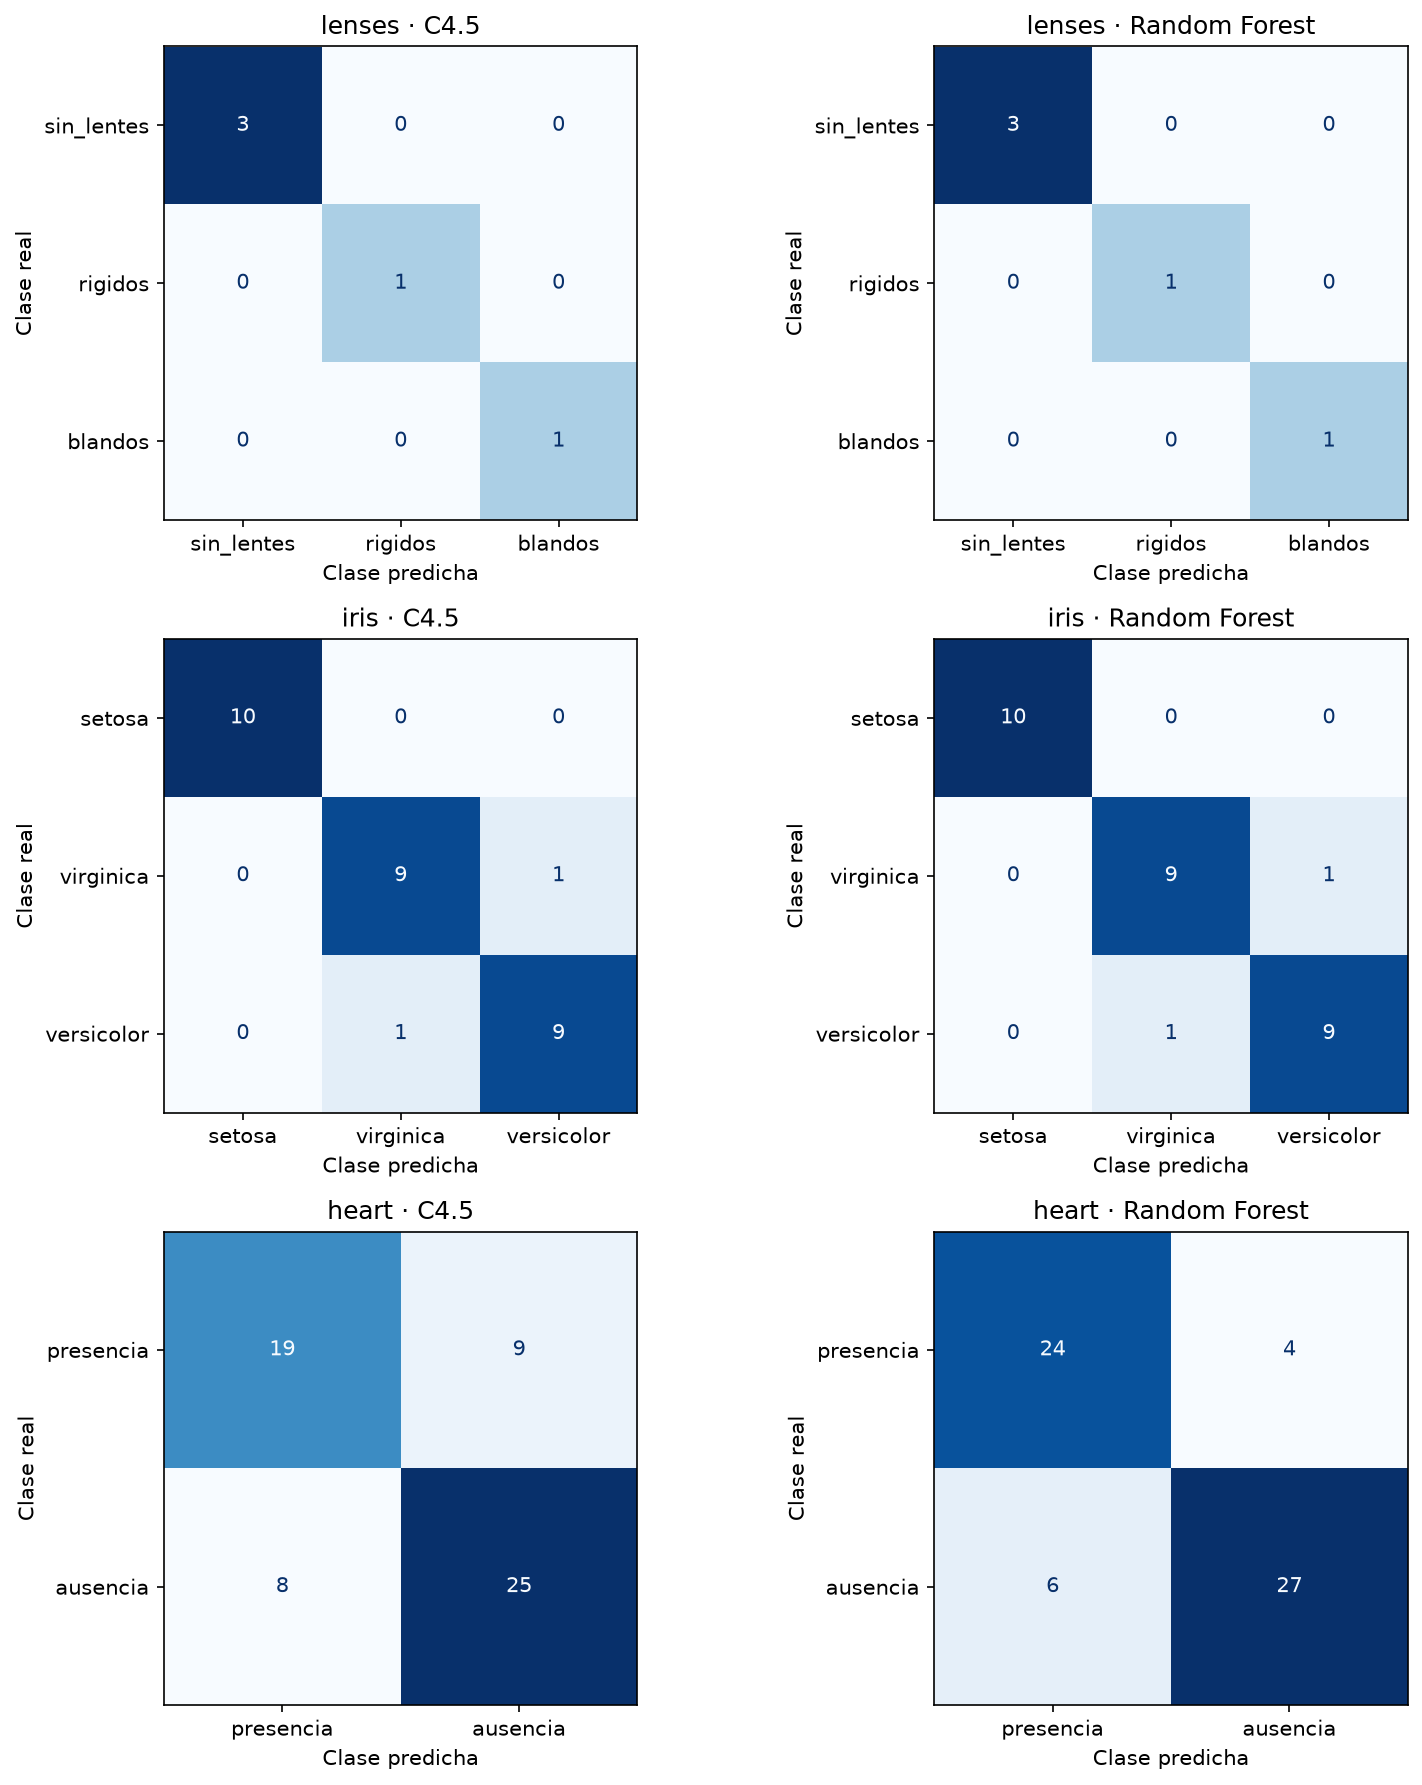

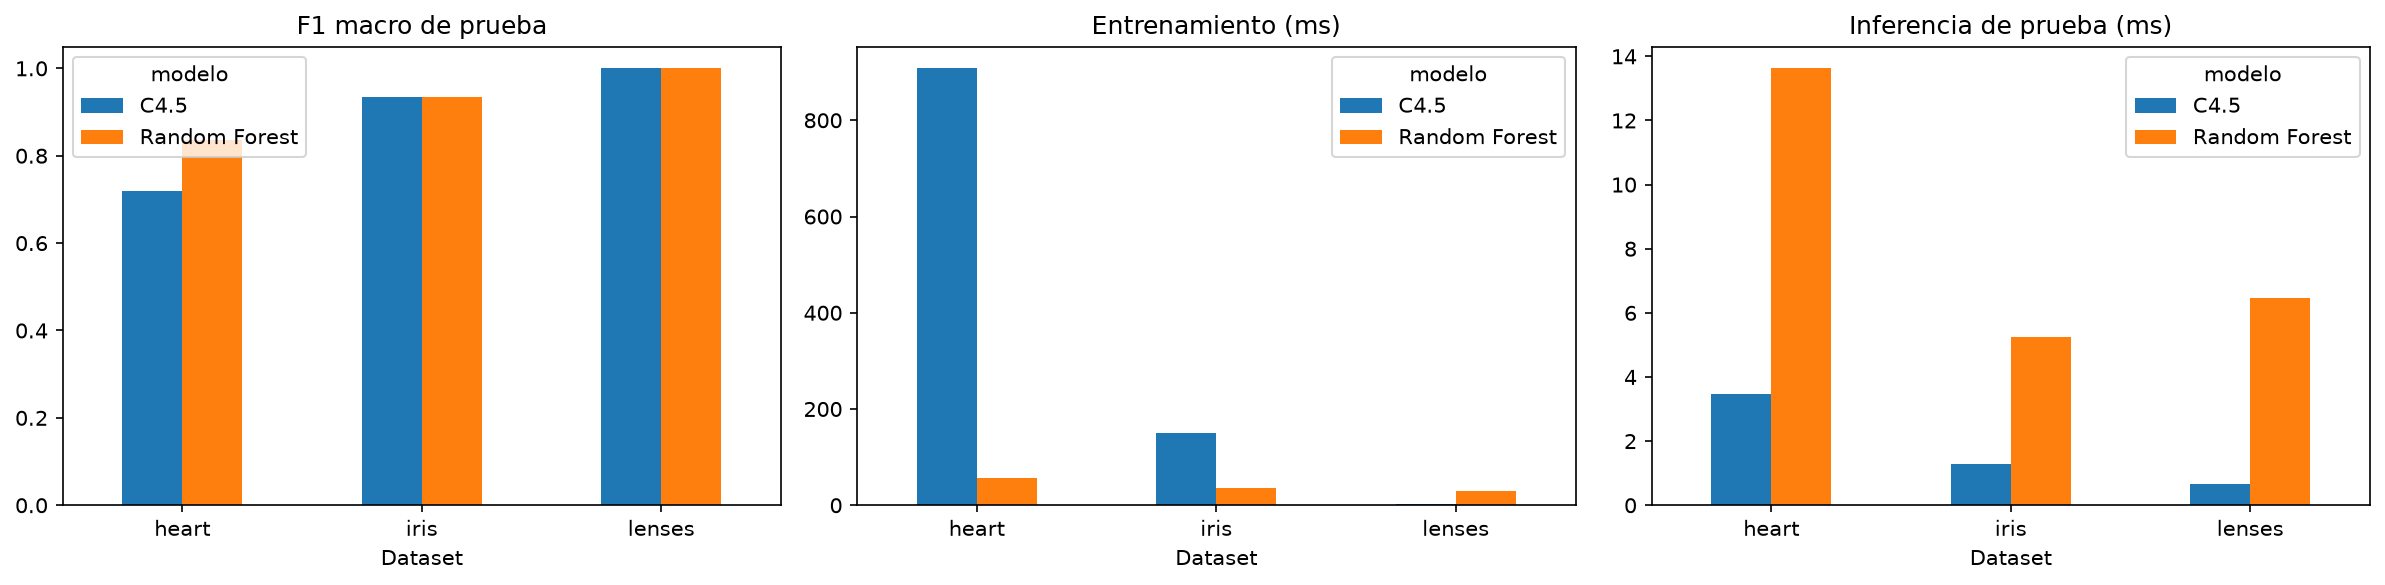

conjunto               entrenamiento  prueba  brecha_entrenamiento_prueba
dataset modelo                                                           
heart   C4.5                  0.8077  0.7186                       0.0891
        Random Forest         1.0000  0.8357                       0.1643
iris    C4.5                  1.0000  0.9333                       0.0667
        Random Forest         1.0000  0.9333                       0.0667
lenses  C4.5                  0.8320  1.0000                      -0.1680
        Random Forest         1.0000  1.0000                       0.0000

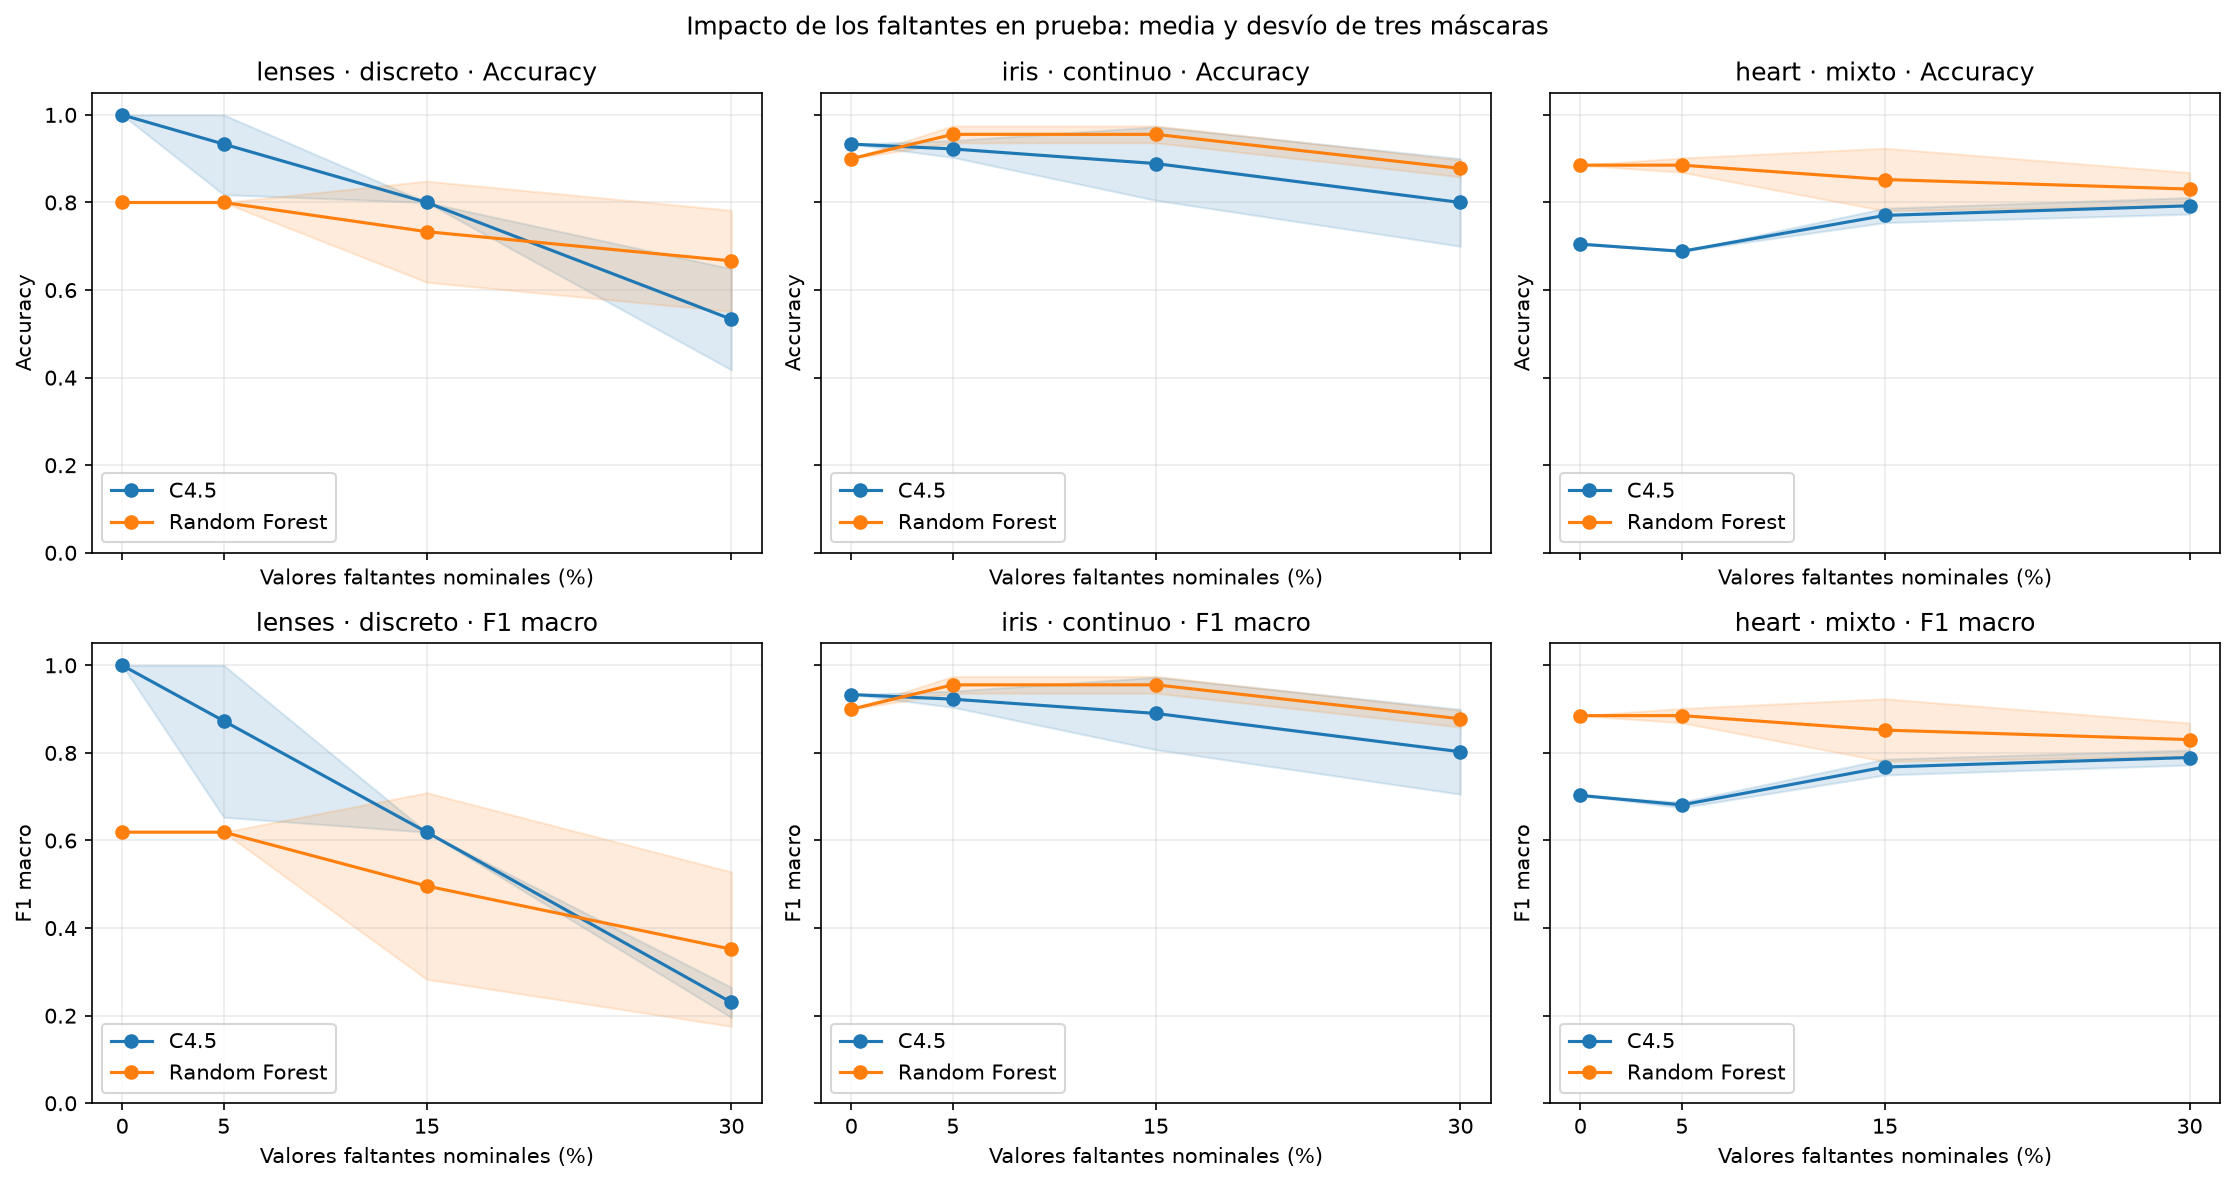

In [10]:
# Matrices de confusión: filas reales y columnas predichas con etiquetas explícitas.
resultados_prueba = resultados_finales.query("conjunto == 'prueba'").copy()
figura_matrices, ejes_matrices = plt.subplots(len(datasets), 2, figsize=(11, 12), squeeze=False)
for posicion, nombre in enumerate(datasets):
    for columna, modelo in enumerate(("C4.5", "Random Forest")):
        registro = resultados_prueba.query("dataset == @nombre and modelo == @modelo").iloc[0]
        ConfusionMatrixDisplay(np.array(registro["matriz_confusion"]),
            display_labels=registro["orden_clases"]).plot(
                ax=ejes_matrices[posicion, columna], colorbar=False, cmap="Blues")
        ejes_matrices[posicion, columna].set(title=f"{nombre} · {modelo}",
                                             xlabel="Clase predicha", ylabel="Clase real")
figura_matrices.set_dpi(150)
figura_matrices.tight_layout()
plt.show()

# Comparar calidad y costo de los modelos elegidos con el mismo protocolo.
figura_comparacion, ejes_comparacion = plt.subplots(1, 3, figsize=(16, 4), dpi=150)
for eje, metrica, titulo in zip(ejes_comparacion,
        ("f1_macro", "tiempo_entrenamiento_ms", "tiempo_inferencia_ms"),
        ("F1 macro de prueba", "Entrenamiento (ms)", "Inferencia de prueba (ms)")):
    resultados_prueba.pivot(index="dataset", columns="modelo", values=metrica).plot.bar(ax=eje)
    eje.set(title=titulo, xlabel="Dataset")
    eje.tick_params(axis="x", rotation=0)
    if metrica == "f1_macro":
        eje.set_ylim(0, 1.05)
figura_comparacion.tight_layout()
plt.show()

# Mostrar la brecha de generalización sin usarla para cambiar los parámetros.
brechas = resultados_finales.pivot(index=["dataset", "modelo"], columns="conjunto", values="f1_macro")
brechas["brecha_entrenamiento_prueba"] = brechas["entrenamiento"] - brechas["prueba"]
display(brechas.round(4))


# Avisar si falta ejecutar la batería antes de intentar acceder a sus resultados.
if "resumen_faltantes" not in globals():
    print("No se generaron las curvas de faltantes: ejecutá por completo la sección 6 "
          "y luego volvé a ejecutar esta sección 8. Las salidas guardadas no "
          "reemplazan las variables de la sesión actual.")
else:
    # Usar las mismas escalas y colores para comparar ambos algoritmos y los tres tipos.
    figura_nulos, ejes_nulos = plt.subplots(2, len(datasets), figsize=(15, 8),
                                            dpi=150, sharex=True, sharey=True, squeeze=False)
    colores_modelos = {"C4.5": "tab:blue", "Random Forest": "tab:orange"}
    for columna, (nombre, datos) in enumerate(datasets.items()):
        for fila, (metrica, etiqueta) in enumerate((("accuracy", "Accuracy"),
                                                   ("f1_macro", "F1 macro"))):
            eje = ejes_nulos[fila, columna]
            for modelo, color in colores_modelos.items():
                curva = resumen_faltantes.query(
                    "dataset == @nombre and modelo == @modelo and conjunto == 'prueba'").sort_values(
                        "fraccion_nulos_objetivo")
                porcentajes = 100 * curva["fraccion_nulos_objetivo"].to_numpy()
                medias = curva[f"{metrica}_media"].to_numpy()
                desvios = curva[f"{metrica}_desvio"].to_numpy()
                eje.plot(porcentajes, medias, marker="o", label=modelo, color=color)
                eje.fill_between(porcentajes, np.clip(medias - desvios, 0, 1),
                                  np.clip(medias + desvios, 0, 1), color=color, alpha=0.15)
            eje.set(title=f"{nombre} · {datos['tipo']} · {etiqueta}",
                    xlabel="Valores faltantes nominales (%)", ylabel=etiqueta,
                    ylim=(0, 1.05), xticks=[0, 5, 15, 30])
            eje.grid(alpha=0.25)
            eje.legend(loc="lower left")
    figura_nulos.suptitle("Impacto de los faltantes en prueba: media y desvío de tres máscaras")
    figura_nulos.tight_layout()
    plt.show()


## 8.1. Barridos estructurales, del bosque y del filtro opcional

Se incorporan barridos de un parámetro por vez en los tres conjuntos de datos, con tres particiones estratificadas (semillas 42, 43 y 44). C4.5 varía profundidad, masa mínima, ganancia mínima, razón de ganancia mínima y filtro. Random Forest varía cantidad de árboles, atributos candidatos, profundidad, criterio y bootstrap. Los demás valores permanecen en su referencia inicial; el bosque utiliza imputación por mediana y moda de entrenamiento. Esto produce 243 entrenamientos y 486 registros de entrenamiento o prueba. La salida conserva parámetros efectivos y semillas y permite repetir cada condición.

Son experimentos descriptivos para observar sensibilidad y sobreajuste; **los resultados de prueba de estos barridos no seleccionan los modelos de la evaluación final**. La selección de la sección 5 utiliza exclusivamente validación interna. No se presenta la mejor puntuación observada entre muchas pruebas como una estimación independiente de rendimiento.

Las curvas muestran Accuracy en entrenamiento y prueba, media y un desvío muestral entre particiones. Su separación ayuda a observar sobreajuste; no demuestra que un ajuste sea óptimo. El filtro es una variante experimental separada: `false` conserva el comportamiento inicial y `true` agrega las dos reglas explicadas en el árbol. Puede cambiar cortes, profundidad y métricas; las pruebas no presuponen una mejora. Las figuras se guardan también en PDF para compartirlas sin perder resolución. Las tablas finales y de faltantes se exportan junto con los resúmenes a archivos regenerables, que alimentan el informe.


Barridos de lenses, semilla 42: completos.


Barridos de lenses, semilla 43: completos.


Barridos de lenses, semilla 44: completos.


Barridos de iris, semilla 42: completos.


Barridos de iris, semilla 43: completos.


Barridos de iris, semilla 44: completos.


Barridos de heart, semilla 42: completos.


Barridos de heart, semilla 43: completos.


Barridos de heart, semilla 44: completos.


,dataset,modelo,parametro_variado,valor_parametro,accuracy_media,accuracy_desvio,f1_macro_media
1,lenses,C4.5,profundidad_maxima,2,0.8667,0.2309,0.8704
3,lenses,C4.5,profundidad_maxima,4,0.7333,0.3055,0.6582
5,lenses,C4.5,profundidad_maxima,null,0.7333,0.3055,0.6582
7,lenses,C4.5,minimo_muestras_division,2,0.7333,0.3055,0.6582
9,lenses,C4.5,minimo_muestras_division,10,0.8000,0.3464,0.7667
...,...,...,...,...,...,...,...
153,heart,Random Forest,profundidad_maxima,null,0.7978,0.0825,0.7921
155,heart,Random Forest,criterio,"""gini""",0.7978,0.0825,0.7921
157,heart,Random Forest,criterio,"""entropy""",0.7814,0.0825,0.7764
159,heart,Random Forest,usar_bootstrap,true,0.7978,0.0825,0.7921


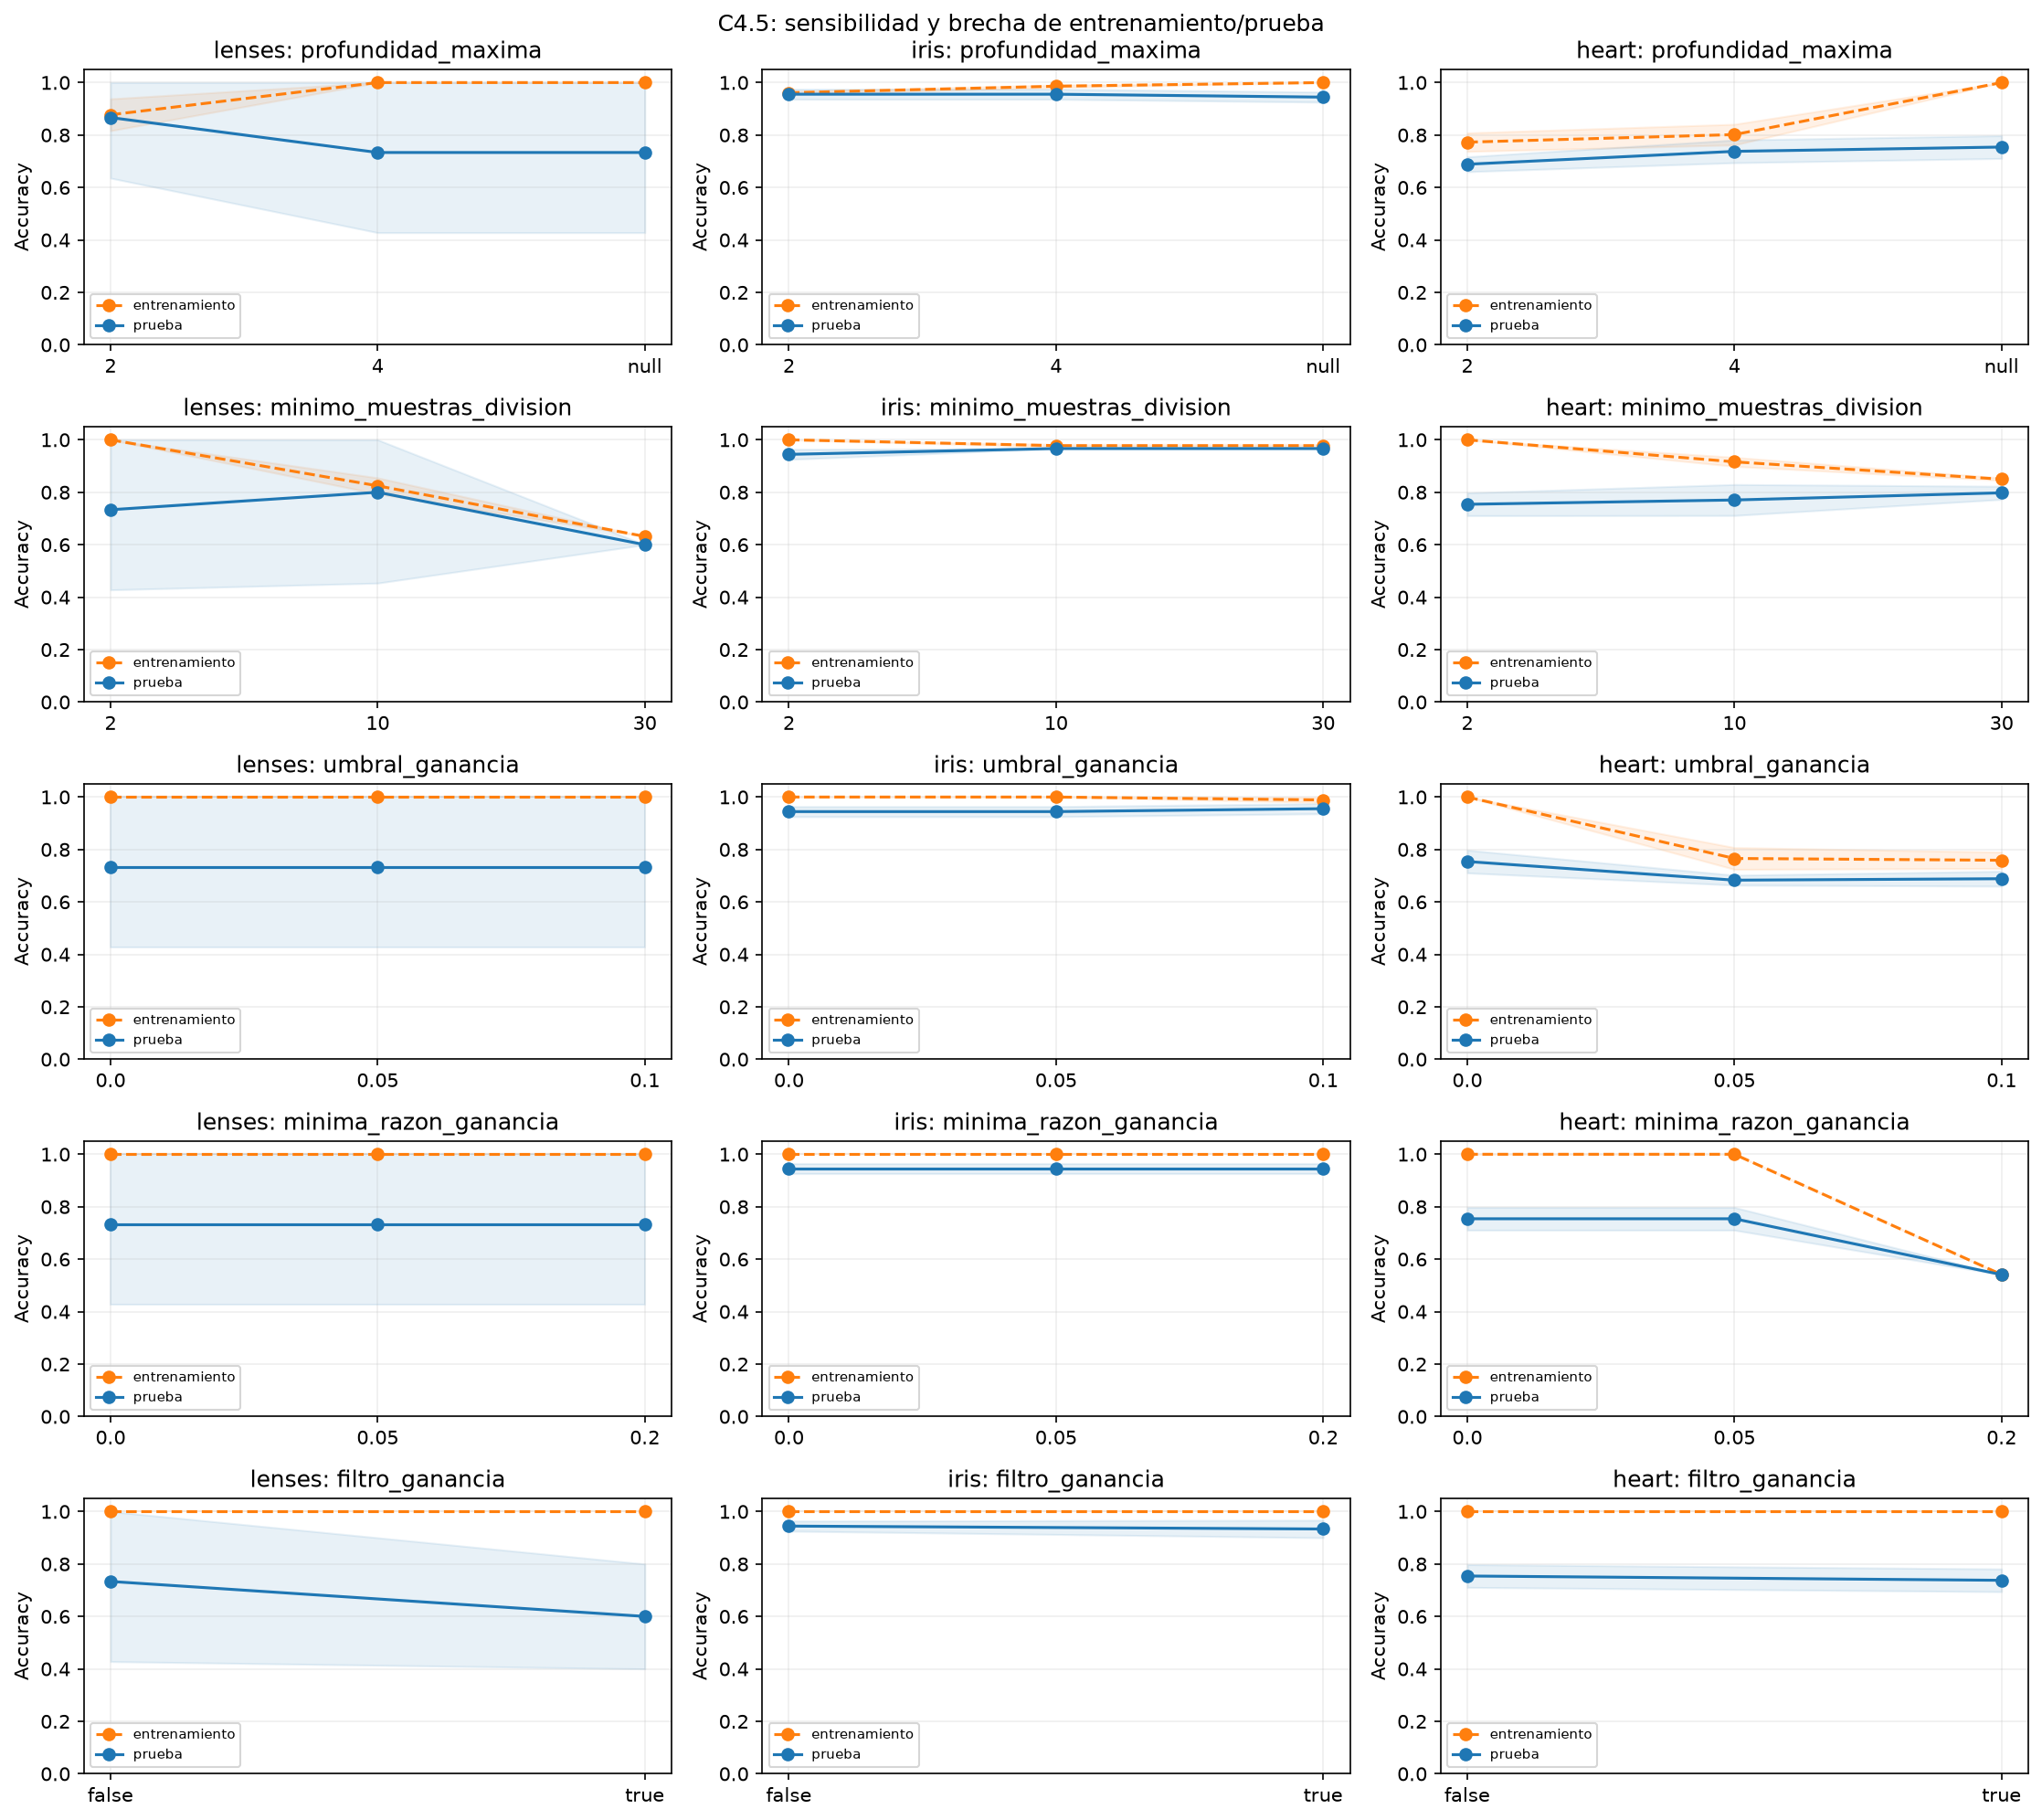

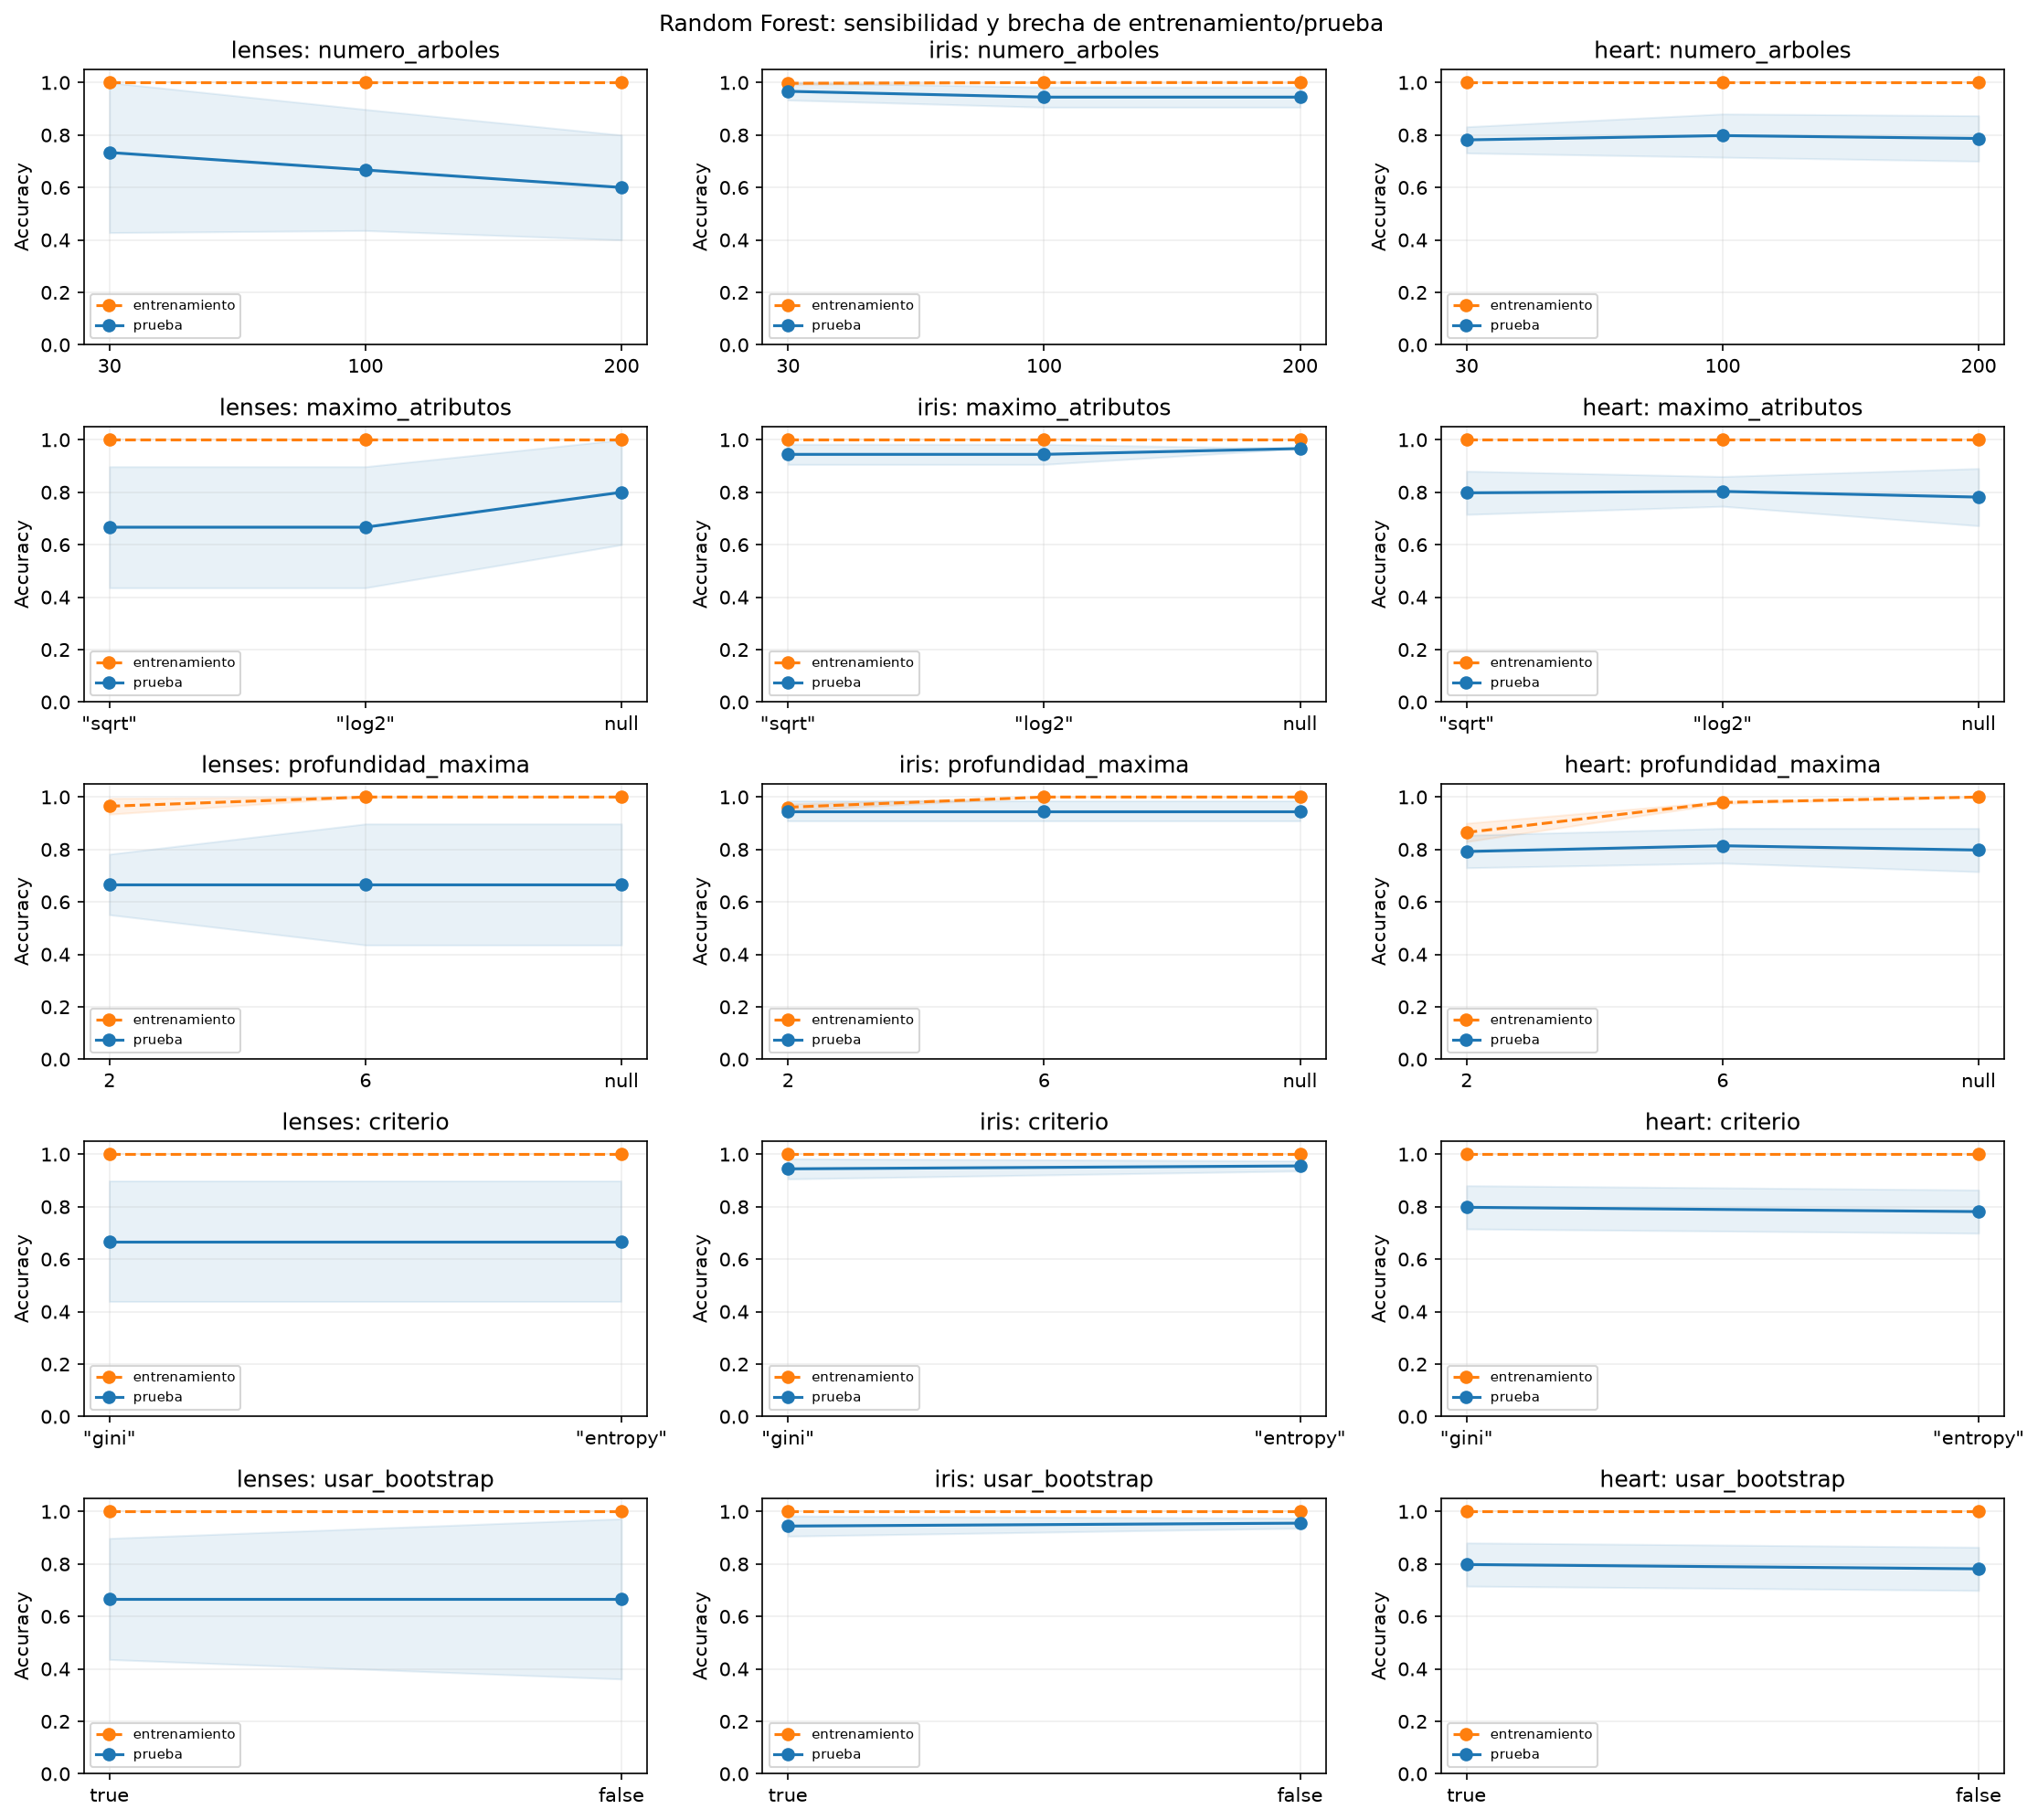

Resultados y figuras exportados; barridos descriptivos completos.


In [11]:
# Ejecutar los valores fijados de antemano sobre las mismas particiones por semilla.
resultados_barridos = ejecutar_barridos_parametros(datasets)
resumen_barridos = resumir_barridos(resultados_barridos)
assert len(resultados_barridos) == 486
assert resultados_barridos.id_ejecucion.nunique() == 243
assert resumen_barridos.repeticiones.eq(3).all()
display(resumen_barridos.query("conjunto == 'prueba'")[["dataset", "modelo", "parametro_variado",
    "valor_parametro", "accuracy_media", "accuracy_desvio", "f1_macro_media"]].round(4))

# Graficar todos los valores en su orden original; el mismo color identifica cada conjunto.
carpeta_figuras = RAIZ / "paper/figuras"
carpeta_figuras.mkdir(exist_ok=True)
for modelo in ("C4.5", "Random Forest"):
    parametros = list(dict.fromkeys(resumen_barridos.loc[resumen_barridos.modelo.eq(modelo), "parametro_variado"]))
    figura_barridos, ejes = plt.subplots(len(parametros), len(datasets),
        figsize=(15, 2.7 * len(parametros)), dpi=150, squeeze=False)
    for fila, parametro in enumerate(parametros):
        for columna, nombre in enumerate(datasets):
            eje = ejes[fila, columna]
            for conjunto, estilo, color in (("entrenamiento", "--", "tab:orange"), ("prueba", "-", "tab:blue")):
                curva = resumen_barridos.query("modelo == @modelo and dataset == @nombre "
                    "and parametro_variado == @parametro and conjunto == @conjunto").sort_values("orden_valor")
                medias, desvios = curva.accuracy_media.to_numpy(), curva.accuracy_desvio.to_numpy()
                eje.plot(curva.orden_valor, medias, linestyle=estilo, color=color, marker="o", label=conjunto)
                eje.fill_between(curva.orden_valor, np.clip(medias - desvios, 0, 1),
                    np.clip(medias + desvios, 0, 1), color=color, alpha=0.1)
                eje.set_xticks(curva.orden_valor, curva.valor_parametro)
            eje.set(title=f"{nombre}: {parametro}", ylabel="Accuracy", ylim=(0, 1.05))
            eje.grid(alpha=0.2)
            eje.legend(fontsize=7, loc="lower left")
    figura_barridos.suptitle(f"{modelo}: sensibilidad y brecha de entrenamiento/prueba")
    figura_barridos.tight_layout()
    figura_barridos.savefig(carpeta_figuras / ("c45_barridos.pdf" if modelo == "C4.5" else "rf_barridos.pdf"))
    plt.show()

# Exportar figuras y las mismas tablas usadas en pantalla, sin resultados transcritos.
figura_comparacion.savefig(carpeta_figuras / "comparacion.pdf")
figura_nulos.savefig(carpeta_figuras / "faltantes.pdf")
exportar_resultados_experimentales(resultados_base, resultados_finales, resumen_faltantes, resumen_barridos)
print("Resultados y figuras exportados; barridos descriptivos completos.")


## 9. Lectura de resultados y trabajo por completar

Las salidas anteriores permiten comparar ambos algoritmos sobre atributos discretos, continuos y mixtos, comprobar que se respeta el mismo protocolo y observar el efecto de una exploración mínima y de una batería de cuatro porcentajes de faltantes con tres máscaras por porcentaje. Las conclusiones deben limitarse a esos datos y esas configuraciones. La cantidad pequeña de casos y una sola partición impiden asegurar que una diferencia se repita en otros problemas.

`resultados_base`, `resultados_exploracion`, `resultados_finales`, `resultados_faltantes`, `diferencias_faltantes` y `resumen_faltantes`, `resultados_barridos` y `resumen_barridos` conservan los registros completos. Para obtener resultados nuevos se reinicia el kernel y se ejecutan todas las celdas en orden. Se requieren Python, NumPy, pandas, scikit-learn, Matplotlib e IPython, las definiciones de los dos algoritmos y los archivos de datos locales. Las mismas rutas relativas funcionan en un entorno Colab cuando la carpeta del proyecto está disponible y es el directorio de trabajo.

[MEJORA OPCIONAL — SIN HU EXCLUSIVA: AMPLIAR LAS TRES SEMILLAS DE PARTICIONADO YA INCORPORADAS, USAR VALIDACIÓN CRUZADA O REPETIR TIEMPOS EN CONDICIONES CONTROLADAS. LA VARIACIÓN ENTRE MÁSCARAS Y ENTRE LAS TRES PARTICIONES YA SE RESUME EN LAS TABLAS.]





[PENDIENTE OBLIGATORIO — HU-20: VALIDAR LA EJECUCIÓN COMPLETA DE TODOS LOS NOTEBOOKS DESDE CERO EN UNA SESIÓN LIMPIA DE GOOGLE COLAB. UNA EJECUCIÓN LOCAL CORRECTA NO ACREDITA ESA COMPROBACIÓN.]

[PENDIENTE OBLIGATORIO — HU-16: REVISAR LOS DATOS PERSONALES DE LA PORTADA Y REALIZAR LA APROBACIÓN EDITORIAL FINAL DEL INFORME. LAS TABLAS Y FIGURAS SE REGENERAN CON LOS EXPERIMENTOS ACTUALES.]
